# PDAN8412 POE Part 3: Classifying real and fake faces with a Convolutional Neural Network

**Student number:** ST10365068
This notwbook use code from class notebooks, the ones from in class lectures and are mentioned throughout the notebook because its based on those notebooks. 


### Setup and imports

This section loads the libraries, fixes the random seed, sets up the folders and checks that TensorFlow can see the Apple Metal GPU of the laptop.

In [1]:
# Libraries used in this notebook
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide TensorFlow start up messages
import tensorflow as tf                    # imported before pandas, as in Ice Task 3
import time
import random
import shutil
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             log_loss, confusion_matrix, classification_report, roc_curve)

This code brings in every library the notebook needs. TensorFlow and its Keras layers build and train the CNN, and the `EarlyStopping` callback stops training when the model stops improving. Pillow (`PIL`) opens image files for the quality checks, `hashlib` makes an MD5 fingerprint of each file to find duplicates, and `shutil` copies files into the working subset. Pandas and NumPy handle tables and arrays, Matplotlib and Seaborn draw the charts, and scikit learn supplies the evaluation metrics. 

**What the output shows.** The cell prints nothing, which means every library loaded without an error in my TensorFlow Metal conda environment.

In [2]:
# Seed 42 for Python, NumPy and TensorFlow so the results can be repeated
seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

# Folders: this notebook sits inside ST10365068_PDAN8412_POE_PART3
base_dir = Path.cwd()
data_dir = base_dir / "Datasets" / "real_vs_fake" / "real-vs-fake"
subset_dir = base_dir / "data_subset"
fig_dir = base_dir / "figures"
out_dir = base_dir / "outputs"
for folder in [subset_dir, fig_dir, out_dir]:
    folder.mkdir(exist_ok=True)

def save_fig(name):
    # Every chart is saved for the report in the same way
    plt.savefig(fig_dir / name, dpi=150, bbox_inches="tight")

sns.set_theme(style="whitegrid")
print("TensorFlow version:", tf.__version__)
print("Metal GPU visible :", tf.config.list_physical_devices("GPU"))
print("Test sum on the GPU:", float(tf.reduce_sum(tf.ones(3))))
print("Dataset folder found:", data_dir.exists())

TensorFlow version: 2.18.0
Metal GPU visible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Test sum on the GPU: 3.0
Dataset folder found: True


I0000 00:00:1795123470.494912  777019 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1795123470.495065  777019 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


This code sets the random seed to 42 for Python, NumPy and TensorFlow. Many steps depend on chance, such as which images are sampled, how the training images are shuffled and the starting weights of every network, so fixing the seed means that a second run gives the same subset and very similar models. Training on a GPU can still add tiny differences between runs, so the exact numbers may move slightly in the last decimal places. T

### 4.1 Loading and Inspecting the Dataset

This section confirms that the unzipped dataset is in place, shows how its folders are organised, counts every image in the full set of 140,000 and looks at what a single image is made of.

In [3]:
# Show the folder structure of the unzipped dataset
print("Datasets folder:", sorted(p.name for p in (base_dir / "Datasets").iterdir()))
print()
print(data_dir.relative_to(base_dir))
for split in sorted(os.listdir(data_dir)):
    print("   ", split)
    for label in sorted(os.listdir(data_dir / split)):
        files = sorted(os.listdir(data_dir / split / label))
        print(f"        {label:<5} {len(files):>6} files   first file: {files[0]}")

Datasets folder: ['archive (1).zip', 'real_vs_fake', 'test.csv', 'train.csv', 'valid.csv']

Datasets/real_vs_fake/real-vs-fake
    test
        fake   10000 files   first file: 00276TOPP4.jpg
        real   10000 files   first file: 00001.jpg
    train


        fake   50000 files   first file: 001DDU0NI4.jpg
        real   50000 files   first file: 00000.jpg
    valid


        fake   10000 files   first file: 00483R5CC4.jpg
        real   10000 files   first file: 00005.jpg


This code lists what is inside the `Datasets` folder and then walks through the image folders of the dataset. For each split (train, valid and test) it prints the two class folders, how many files each one holds and the name of the first file. Seeing the structure first matters because `image_dataset_from_directory`, the loader used in class, takes the class labels straight from the folder names, so the folders have to be laid out correctly before anything else is done.

**What the output shows.** The `Datasets` folder holds the original zip, the unzipped `real_vs_fake` folder and three CSV files that come with the dataset. The training split has 50,000 fake and 50,000 real images, and the valid and test splits each have 10,000 of each. 

In [4]:
# Count every image per split and class in the full dataset
splits = ["train", "valid", "test"]
classes = ["real", "fake"]

rows = []
for split in splits:
    for label in classes:
        for name in sorted(os.listdir(data_dir / split / label)):
            rows.append({"split": split, "label": label, "file": name,
                         "path": str(data_dir / split / label / name)})
full_df = pd.DataFrame(rows)

counts_full = pd.crosstab(full_df["split"], full_df["label"], margins=True, margins_name="total")
counts_full = counts_full.reindex(index=splits + ["total"], columns=classes + ["total"])
counts_full.to_csv(out_dir / "01_full_counts.csv")
print("Total images in the full dataset:", len(full_df))
counts_full

Total images in the full dataset: 140000


label,real,fake,total
split,,,
train,50000,50000,100000
valid,10000,10000,20000
test,10000,10000,20000
total,70000,70000,140000


This code builds one table, `full_df`, with a row for every file in the dataset, holding its split, its label (taken from the folder name), its file name and its full path. Keeping every file in one table makes the later quality checks and the sampling much easier, because each check simply adds a new column. The code then counts the images per split and class with a cross table, adds totals, prints the grand total and saves the table as `outputs/01_full_counts.csv`.

**What the output shows.** The full dataset holds 140,000 images: 70,000 real and 70,000 fake. The training split has 100,000 images, and the valid and test splits have 20,000 each, which is roughly a 71, 14 and 14 percent split. Every split is perfectly balanced, with exactly half real and half fake images, so the classes never need rebalancing.

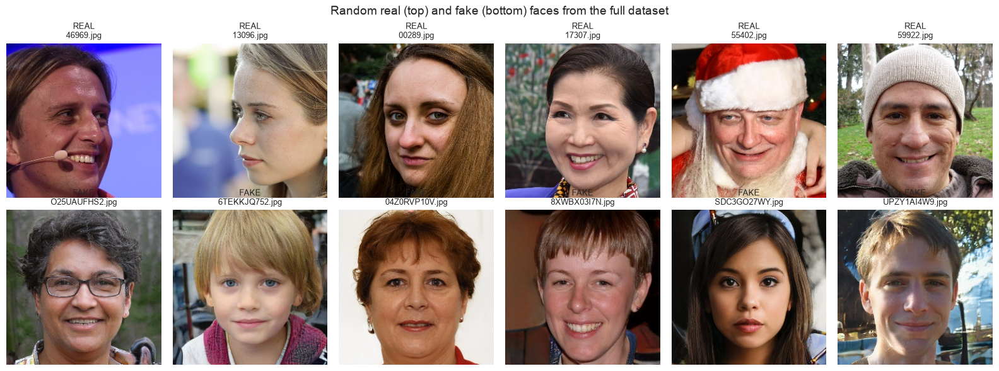

In [5]:
# A labelled grid of random real and fake faces from the full training split
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for r, label in enumerate(classes):
    picks = full_df[(full_df["split"] == "train") & (full_df["label"] == label)].sample(6, random_state=seed)
    for c, (_, row) in enumerate(picks.iterrows()):
        axes[r, c].imshow(Image.open(row["path"]))
        axes[r, c].set_title(f"{label.upper()}\n{row['file']}", fontsize=9)
        axes[r, c].axis("off")
plt.suptitle("Random real (top) and fake (bottom) faces from the full dataset", fontsize=14)
plt.tight_layout()
save_fig("01_random_real_and_fake.png")
plt.show()

This code picks six random real faces and six random fake faces from the training split, using the seed so the same faces appear every time, and shows them in a labelled grid with the class and file name above each face. Looking at real examples before modelling is important because it shows how hard the task is for a person and what kind of variation the CNN will have to cope with. The chart is saved as `figures/01_random_real_and_fake.png`.

**What the output shows.** The grid shows how varied and how convincing the faces are. The real faces include people of different ages wearing hats, a headset microphone and a Santa costume, against busy backgrounds. The fake faces look just as natural at this size, with glasses, earrings, children and adults, and no obvious sign that they were generated. This shows that a person cannot easily separate the classes by eye, so the CNN will have to learn subtle details rather than an obvious difference.

In [6]:
# Inspect one image as an array, in the style of ICE Task 4
sample_path = full_df.loc[0, "path"]
with Image.open(sample_path) as img:
    sample_array = np.array(img)

print("File            :", Path(sample_path).relative_to(data_dir))
print("Shape           :", sample_array.shape)
print("Height (rows)   :", sample_array.shape[0])
print("Width (columns) :", sample_array.shape[1])
print("Channels        :", sample_array.shape[2])
print("Data type       :", sample_array.dtype)
print("Min pixel value :", sample_array.min())
print("Max pixel value :", sample_array.max())
print("Top left pixel [R, G, B]:", sample_array[0, 0])

File            : train/real/00000.jpg
Shape           : (256, 256, 3)
Height (rows)   : 256
Width (columns) : 256
Channels        : 3
Data type       : uint8
Min pixel value : 0
Max pixel value : 255
Top left pixel [R, G, B]: [  4 131 146]


This code opens one image and turns it into a NumPy array, which is how a computer actually sees a picture. As explained in my ICE Task 4, an image becomes a three dimensional array with the shape height by width by channels. The height is the number of pixel rows, the width is the number of pixel columns and the channels are the red, green and blue colour layers. Each value is a whole number from 0 (none of that colour) to 255 (full strength), stored as `uint8`. The code prints the shape, each dimension, the data type, the smallest and largest pixel value, and the three colour values of the top left pixel.

**What the output shows.** The image has the shape (256, 256, 3): 256 rows of pixels, 256 columns and 3 colour channels. The values are stored as `uint8`, the smallest value is 0 and the largest is 255, so the image uses the full range of brightness. The top left pixel is [4, 131, 146], which means almost no red, a fair amount of green and a little more blue, a teal colour. The training pipeline will later resize these arrays to 128 by 128 and scale them to 0 to 1, and add a fourth batch dimension at the front.

### 4.2 Data Quality Check

This section looks for problems that could mislead the model: wrong file types, corrupt files, images of the wrong size or colour mode, blank images and exact duplicates. Every check runs on the full set of 140,000 images because each one only takes seconds on this laptop. The findings are collected in one summary table at the end of the section.

In [7]:
# File extensions and file sizes per class on the full dataset
full_df["extension"] = full_df["file"].str.rsplit(".", n=1).str[-1].str.lower()
full_df["size_kb"] = full_df["path"].map(lambda p: os.path.getsize(p) / 1024)

print("File extensions per class:")
print(pd.crosstab(full_df["extension"], full_df["label"]))
print()
size_table = full_df.groupby(["label", "split"])["size_kb"].describe().round(1)
size_table.to_csv(out_dir / "02_file_size_by_class.csv")
size_table

File extensions per class:
label       fake   real
extension              
jpg        70000  70000



count  mean  std   min   25%   50%   75%   max
label split                                                  
fake  test   10000.0  27.7  3.9  15.4  25.0  27.3  30.0  52.3
      train  50000.0  27.8  3.9  15.5  25.1  27.4  30.0  51.4
      valid  10000.0  27.7  3.8  16.0  25.1  27.2  30.0  49.6
real  test   10000.0  28.3  3.9  15.8  25.6  28.1  30.7  45.6
      train  50000.0  28.3  3.9  13.5  25.6  28.0  30.7  50.2
      valid  10000.0  28.2  3.8  13.6  25.6  28.0  30.6  50.5

This code follows the lecturer's EDA notebook, which checks for wrong file extensions before anything else. It reads the extension of every file name and counts the extensions per class, so any file that is not a JPEG would stand out. It then reads the size of every file in kilobytes and summarises the sizes for each class and split (count, mean, spread, smallest, quartiles and largest). File size is worth checking because a damaged file is often unusually small, and because a large difference in file size between real and fake images could later give the model a shortcut, which is tested properly in 4.5. The table is saved as `outputs/02_file_size_by_class.csv`.

**What the output shows.** Every one of the 140,000 files is a JPEG (70,000 per class), so no file has a wrong extension. File sizes are very similar between the classes and between the splits. Real images average about 28.2 to 28.3 KB and fake images about 27.7 to 27.8 KB, with the same spread of about 3.9 KB in every group. The smallest file is 13.5 KB, which is far too large to be an empty or broken file. The small half a kilobyte gap between real and fake files is tested as a possible shortcut in 4.5.

In [8]:
# One pass over every image: does it open, what size and colour mode is it,
# and how bright (mean grey level) and how contrasted (grey standard deviation) is it?
def inspect_image(path):
    try:
        with Image.open(path) as img:
            img.verify()                      # structural check from the lecturer's EDA notebook
        with Image.open(path) as img:
            width, height, mode = img.width, img.height, img.mode
            img.draft("L", (64, 64))          # fast grey decode at a quarter of the size
            grey = np.asarray(img.convert("L"), dtype=np.float32)
        return width, height, mode, float(grey.mean()), float(grey.std()), False
    except Exception:
        return None, None, None, np.nan, np.nan, True

start = time.time()
checked = [inspect_image(p) for p in full_df["path"]]
columns = ["width", "height", "mode", "brightness", "contrast", "corrupt"]
full_df[columns] = pd.DataFrame(checked, index=full_df.index)
full_df["corrupt"] = full_df["corrupt"].astype(bool)

print(f"Checked {len(full_df):,} images in {time.time() - start:.0f} seconds")
print("Corrupt files :", int(full_df["corrupt"].sum()))
print("Image sizes   :", full_df.groupby(["width", "height"]).size().to_dict())
print("Colour modes  :", full_df["mode"].value_counts().to_dict())

Checked 140,000 images in 43 seconds
Corrupt files : 0
Image sizes   : {(256, 256): 140000}
Colour modes  : {'RGB': 140000}


This code opens every one of the 140,000 images once. First it calls Pillow's `verify()` inside a `try` block, exactly as in the lecturer's EDA notebook, so that a corrupt file is caught and flagged instead of crashing the notebook. It then reopens the image to read its width, height and colour mode, and decodes a small grey copy (a quarter of the size, which JPEG can do very quickly) to measure two numbers: brightness, the average grey level from 0 to 255, and contrast, the standard deviation of the grey levels. Measuring these on a smaller grey copy keeps the whole pass fast while still describing the image well. The brightness and contrast values are reused later in the EDA and in the shortcut checks. The output reports how long the pass took, how many files are corrupt, which image sizes occur and which colour modes occur.

**What the output shows.** All 140,000 images were checked in 46 seconds. No file is corrupt, every image is 256 by 256 pixels and every image is in RGB colour mode. This means no files need to be removed for these reasons, every image can be fed to the same input layer, and resizing only has to scale the images down and never has to fix their shape.

Nearly uniform images: 0
count    140000.00
mean         55.82
std          10.92
min          15.31
25%          48.23
50%          55.51
75%          63.11
max         108.17
Name: contrast, dtype: float64


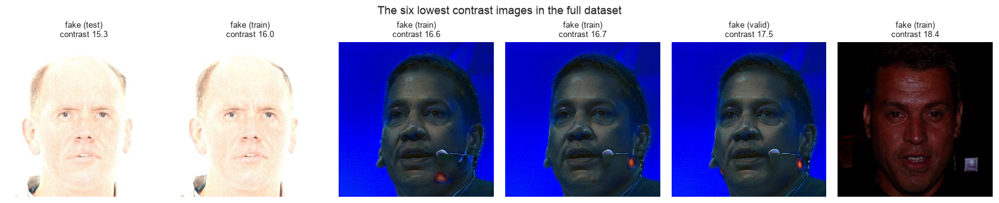

In [9]:
# Blank or nearly uniform images have almost no variation in their grey levels
blank_std = 10   # a grey standard deviation below 10 out of 255 means an almost flat image
blank = full_df[full_df["contrast"] < blank_std]
print("Nearly uniform images:", len(blank))
print(full_df["contrast"].describe().round(2))

lowest = full_df.nsmallest(6, "contrast")
fig, axes = plt.subplots(1, 6, figsize=(16, 3.4))
for ax, (_, row) in zip(axes, lowest.iterrows()):
    ax.imshow(Image.open(row["path"]))
    ax.set_title(f"{row['label']} ({row['split']})\ncontrast {row['contrast']:.1f}", fontsize=9)
    ax.axis("off")
plt.suptitle("The six lowest contrast images in the full dataset", fontsize=13)
plt.tight_layout()
save_fig("02_lowest_contrast_images.png")
plt.show()

This code looks for blank or nearly blank images, such as a frame that is all black or all grey, which would teach the model nothing about faces. It uses the contrast measured in the previous cell. The cut off `blank_std = 10` is set here: on a scale of 0 to 255, a standard deviation under 10 means the whole image is almost one flat shade. The code counts the images under the cut off, prints a summary of contrast across the dataset and shows the six lowest contrast images, so the cut off can be checked by eye rather than trusted blindly. The chart is saved as `figures/02_lowest_contrast_images.png`.

**What the output shows.** No image falls under the cut off: the lowest contrast in the whole dataset is 15.31 and the average is 55.82, so there are no blank frames. The six lowest contrast images are all real looking faces in extreme lighting: two are washed out to almost white, three are lit in deep blue on a stage and one is very dark. They are kept, because a recognition system at the publisher's premises will also meet faces in poor lighting. The chart also reveals something the MD5 check in the next cell cannot catch. The same fake man in blue light appears three times (twice in train and once in valid) and the same washed out fake man appears twice (once in test and once in train). These images are near duplicates rather than exact copies, so their bytes differ. This means a few very similar fake faces may sit on both sides of a split, which is a known limitation of this dataset. A perceptual hash, which compares how images look instead of their bytes, would be needed to find them all.

In [10]:
# Exact duplicates: two files with the same MD5 hash are byte for byte copies
def md5_of(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

start = time.time()
full_df["md5"] = full_df["path"].map(md5_of)
dups = full_df[full_df.duplicated("md5", keep=False)]
groups = dups.groupby("md5").agg(copies=("file", "size"),
                                 splits=("split", lambda s: " + ".join(sorted(set(s)))),
                                 labels=("label", lambda s: " + ".join(sorted(set(s)))))
within_split = int((~groups["splits"].str.contains("+", regex=False)).sum())
across_split = int(groups["splits"].str.contains("+", regex=False).sum())
across_label = int(groups["labels"].str.contains("+", regex=False).sum())
name_clash = int(full_df.duplicated("file", keep=False).sum())

print(f"Hashed {len(full_df):,} files in {time.time() - start:.0f} seconds")
print("Files that have an exact copy  :", len(dups))
print("Duplicate groups in one split  :", within_split)
print("Duplicate groups across splits :", across_split)
print("Duplicate groups with both labels:", across_label)
print("File names used more than once :", name_clash)
groups.head(10)

Hashed 140,000 files in 15 seconds
Files that have an exact copy  : 0
Duplicate groups in one split  : 0
Duplicate groups across splits : 0
Duplicate groups with both labels: 0
File names used more than once : 0


,copies,splits,labels
md5,,,


This code gives every file an MD5 hash, which is a short fingerprint calculated from all of its bytes. Two files with the same fingerprint are exact copies, even if they have different names or sit in different folders. Duplicates matter for two reasons. A copy inside the training set makes the model see the same face twice, and a copy that sits in both the training and the test set is leakage, because the model would be tested on a face it has already learned, which makes the test score look better than it really is. A copy with both a real and a fake label would also be contradictory. The code counts duplicates within one split, across splits and across labels, and also counts file names that are used more than once, then shows up to ten duplicate groups.

**What the output shows.** All 140,000 files were hashed in 16 seconds and no two files share a fingerprint. There are no exact duplicates within a split, none across splits and none with both a real and a fake label, and every file name is used only once. So there is no exact copy leakage between the training, validation and test sets, although the previous cell showed that some near duplicates do exist.

In [11]:
# Collect every check in one data quality summary table
full_df["flagged"] = (full_df["corrupt"] | (full_df["contrast"] < blank_std)
                      | full_df.duplicated("md5", keep=False))

def action(n):
    return "Leave these files out of the subset" if n else "Nothing to remove"

n_corrupt, n_blank, n_dups = int(full_df["corrupt"].sum()), len(blank), len(dups)
sizes = ", ".join(f"{w} by {h}: {n:,}" for (w, h), n in full_df.groupby(["width", "height"]).size().items())
quality = pd.DataFrame([
    ["File extensions", ", ".join(f"{k}: {v:,}" for k, v in full_df["extension"].value_counts().items()), "Nothing to remove"],
    ["Corrupt files (Pillow verify)", f"{n_corrupt}", action(n_corrupt)],
    ["Image size", sizes, "Resize to one size when loading"],
    ["Colour mode", ", ".join(f"{k}: {v:,}" for k, v in full_df["mode"].value_counts().items()), "Keep all three colour channels"],
    [f"Nearly uniform images (contrast below {blank_std})", f"{n_blank}", action(n_blank)],
    ["Exact duplicates (MD5)", f"{n_dups} files in {len(groups)} groups", action(n_dups)],
    ["Duplicates across splits", f"{across_split} groups", action(across_split)],
    ["Duplicates with both labels", f"{across_label} groups", action(across_label)],
    ["Total flagged files", f"{int(full_df['flagged'].sum())}", "Excluded before sampling in 4.3"],
], columns=["Check (full dataset of 140,000)", "Result", "Action"])
quality.to_csv(out_dir / "03_data_quality_summary.csv", index=False)
quality

,"Check (full dataset of 140,000)",Result,Action
0,File extensions,"jpg: 140,000",Nothing to remove
1,Corrupt files (Pillow verify),0,Nothing to remove
2,Image size,"256 by 256: 140,000",Resize to one size when loading
3,Colour mode,"RGB: 140,000",Keep all three colour channels
4,Nearly uniform images (contrast below 10),0,Nothing to remove
5,Exact duplicates (MD5),0 files in 0 groups,Nothing to remove
6,Duplicates across splits,0 groups,Nothing to remove
7,Duplicates with both labels,0 groups,Nothing to remove
8,Total flagged files,0,Excluded before sampling in 4.3


This code gathers every check from this section into one summary table with three columns: what was checked, what was found and what will be done about it. All the numbers are pulled straight from the earlier results, so the table cannot drift out of date if the notebook is run again. It also adds a `flagged` column to `full_df` that marks every file that is corrupt, nearly blank or part of a duplicate group. When a duplicate is found, every copy is flagged and not just the second one, because keeping one copy could still leave a face in one split that is also in another. The flagged files are not deleted from the dataset; they are simply left out when the working subset is sampled in 4.3, which keeps the original images untouched. The table is saved as `outputs/03_data_quality_summary.csv`.

**What the output shows.** The summary table confirms that the dataset is technically clean. Every file is a JPEG, none are corrupt, all are 256 by 256 in RGB, none are blank, and there are no exact duplicates of any kind, so 0 files are flagged and none had to be left out of the subset. The only actions needed are to resize the images to one input size and to keep the three colour channels. The near duplicates found by eye in the lowest contrast check are recorded as a limitation in the text rather than in this table, because the MD5 check cannot detect them.

### 4.3 Data Cleaning and Building the Working Subset

Training one CNN on all 140,000 images would take a long time on a laptop, and this project trains around ten models to compare different settings. A smaller working subset keeps every experiment fast enough to run in one sitting while still being large enough to train and judge a CNN properly, and well above the minimum of 10,000 records in the brief. The subset is drawn separately from each of the dataset's own splits (train to train, valid to val and test to test), so a face can never move from one set into another.

In [12]:
# A seeded, balanced random sample from each of the dataset's own splits
train_per_class = 5000
val_per_class = 1000
test_per_class = 1000
sample_sizes = {"train": train_per_class, "valid": val_per_class, "test": test_per_class}

clean_df = full_df[~full_df["flagged"]]
print("Files left out because of the quality checks:", len(full_df) - len(clean_df))

parts = []
for split, n in sample_sizes.items():
    for label in classes:
        pool = clean_df[(clean_df["split"] == split) & (clean_df["label"] == label)]
        parts.append(pool.sample(n=n, random_state=seed))
subset_df = pd.concat(parts, ignore_index=True)
subset_df["subset_split"] = subset_df["split"].replace({"valid": "val"})

print("Images in the working subset:", len(subset_df))
pd.crosstab(subset_df["subset_split"], subset_df["label"]).reindex(index=["train", "val", "test"], columns=classes)

Files left out because of the quality checks: 0
Images in the working subset: 14000


label,real,fake
subset_split,,
train,5000,5000
val,1000,1000
test,1000,1000


This code sets the size of the working subset and then draws it. The sample sizes are set here: 5,000 real and 5,000 fake faces for training, and 1,000 of each for validation and for testing, which gives 14,000 images in total. First every file flagged in 4.2 is removed from the pool of candidates. Then, for every split and class, the code takes a random sample of the required size using the seed, so the same files are chosen every time. Sampling each class separately keeps the subset exactly balanced, and sampling each split separately means a training image can only ever come from the training folder of the original dataset. The dataset calls its middle split `valid`, so the subset calls it `val` to match the folder names used later.

**What the output shows.** No files were left out, since the quality checks flagged nothing. The working subset holds exactly 14,000 images: 5,000 real and 5,000 fake for training, and 1,000 of each for validation and for testing. The subset is perfectly balanced in every split, and at 14,000 images it is well above the 10,000 record minimum in the brief.

In [13]:
# Copy the sample into data_subset/{train,val,test}/{real,fake}/
# Adapted from the Ice Task 1 export pattern: one folder per class and the class name in the file name.
# Changed: shutil.copy2 copies the original bytes instead of re-saving with plt.imsave, so the JPEG is not compressed again.
if subset_dir.exists():
    shutil.rmtree(subset_dir)   # start clean so a rerun gives exactly the same folders
for split in ["train", "val", "test"]:
    for label in classes:
        (subset_dir / split / label).mkdir(parents=True, exist_ok=True)

new_paths = []
for _, row in subset_df.iterrows():
    target = subset_dir / row["subset_split"] / row["label"] / f"{row['label']}_{row['file']}"
    shutil.copy2(row["path"], target)
    new_paths.append(str(target))
subset_df["subset_path"] = new_paths

subset_df[["subset_split", "label", "file", "md5", "subset_path"]].to_csv(out_dir / "04_subset_file_list.csv", index=False)
print(f"{len(subset_df):,} images copied into {subset_dir.name}/")

14,000 images copied into data_subset/


This code writes the sampled images into the `data_subset` folder using the export pattern from my Ice Task 1: a folder for each class inside each split, with the class name also added to the start of the file name so the label stays with the image even if it is moved. There is one deliberate change from Ice Task 1. Ice Task 1 loaded the images with `image_dataset_from_directory`, turned them into arrays and saved them again with `plt.imsave`. Saving a JPEG again compresses it a second time and resizes it, which blurs exactly the tiny pixel details that can give a fake face away. Here `shutil.copy2` copies the original bytes instead, so the subset images are identical to the originals and the originals are never changed. The folder is emptied first so that running the notebook again gives exactly the same subset, and the list of copied files is saved as `outputs/04_subset_file_list.csv`.

**What the output shows.** All 14,000 images were copied into `data_subset`. Because the files were copied byte for byte, they are exactly the same images as in the original dataset, and the original files were not touched.

In [14]:
# Recount the folders and prove that no file appears in two sets
recount = {split: {label: len(os.listdir(subset_dir / split / label)) for label in classes}
           for split in ["train", "val", "test"]}
recount_df = pd.DataFrame(recount).T
recount_df["total"] = recount_df.sum(axis=1)
recount_df.to_csv(out_dir / "05_subset_counts.csv")
print(recount_df, "\n")

hashes = {s: set(subset_df.loc[subset_df["subset_split"] == s, "md5"]) for s in ["train", "val", "test"]}
names = {s: set(subset_df.loc[subset_df["subset_split"] == s, "file"]) for s in ["train", "val", "test"]}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"{a:>5} and {b:<5} share {len(hashes[a] & hashes[b])} files by MD5 and {len(names[a] & names[b])} by name")
print("Unique MD5 hashes in the subset:", subset_df["md5"].nunique(), "of", len(subset_df))

       real  fake  total
train  5000  5000  10000
val    1000  1000   2000
test   1000  1000   2000 

train and val   share 0 files by MD5 and 0 by name
train and test  share 0 files by MD5 and 0 by name
  val and test  share 0 files by MD5 and 0 by name
Unique MD5 hashes in the subset: 14000 of 14000


This code checks the result of the copy instead of assuming it worked, in the same way that Ice Task 1 counted the exported folders. It counts the files that are actually in each class folder of the subset and saves the counts as `outputs/05_subset_counts.csv`. It then proves that the three sets do not overlap. It compares the MD5 fingerprints between every pair of sets, which would catch a copied face even under a different name, and it also compares the original file names. Finally it checks that every one of the 14,000 images has a different fingerprint.

**What the output shows.** The recount matches the plan exactly: 10,000 training images, 2,000 validation images and 2,000 test images, each split evenly between real and fake. The training and validation sets share 0 files by fingerprint and 0 by name, and the same is true for training and test and for validation and test. All 14,000 images have different fingerprints. This proves that no image appears in more than one set, which fixes the overlap problem of the class notebook.

### 4.4 EDA

This section starts from the lecturer's image EDA (class counts, a bar chart, image sizes and aspect ratio) and adds checks that matter for telling real faces from fake ones: sample comparisons, brightness and contrast, colour channels and average faces. Every chart ends with what it means for how the model is trained.

#### 4.4.1 Class Balance

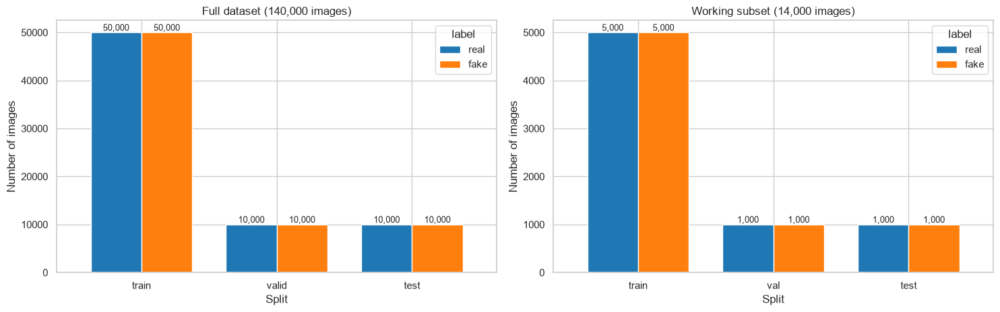

In [15]:
# Class balance for the full dataset and the working subset
colours = {"real": "tab:blue", "fake": "tab:orange"}
full_counts = full_df.groupby(["split", "label"]).size().unstack()[classes].reindex(splits)
sub_counts = subset_df.groupby(["subset_split", "label"]).size().unstack()[classes].reindex(["train", "val", "test"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, counts, title in [(axes[0], full_counts, f"Full dataset ({len(full_df):,} images)"),
                          (axes[1], sub_counts, f"Working subset ({len(subset_df):,} images)")]:
    counts.plot(kind="bar", ax=ax, color=[colours[c] for c in classes], rot=0, width=0.75)
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{v:,.0f}" for v in container.datavalues], fontsize=9)
    ax.set_title(title)
    ax.set_xlabel("Split")
    ax.set_ylabel("Number of images")
plt.tight_layout()
save_fig("03_class_balance.png")
plt.show()

This code draws the class balance as two bar charts side by side, one for the full dataset and one for the working subset, with the count written above every bar. Real faces are always blue and fake faces always orange in this notebook so the charts are easy to compare. The lecturer's EDA notebook starts with this chart because a model trained on unbalanced classes can learn to favour the bigger class and still look accurate. The chart is saved as `figures/03_class_balance.png`.

**What the output shows.** Both charts show perfectly even bars. In the full dataset every split has the same number of real and fake images (50,000 of each in training and 10,000 of each in validation and test), and the subset keeps the same balance with 5,000, 1,000 and 1,000 of each. **What this means for training:** because the classes are equal, a model cannot score well by favouring one class, accuracy is a fair headline metric, random guessing scores 50 percent, and no class weights are needed.

#### 4.4.2 Image Size and Shape

width  height
256    256       140000
Name: images, dtype: int64

Aspect ratios found: {1.0: 140000}


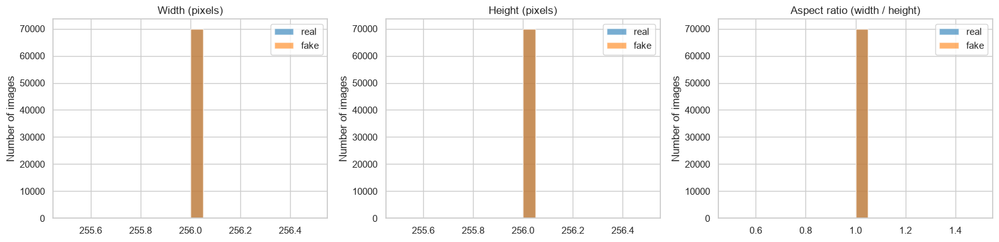

In [16]:
# Width, height and aspect ratio of every image, as in the lecturer's EDA notebook
full_df["aspect_ratio"] = full_df["width"] / full_df["height"]
print(full_df.groupby(["width", "height"]).size().rename("images"))
print("\nAspect ratios found:", full_df["aspect_ratio"].round(3).value_counts().to_dict())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, column, title in zip(axes, ["width", "height", "aspect_ratio"], ["Width (pixels)", "Height (pixels)", "Aspect ratio (width / height)"]):
    for label in classes:
        ax.hist(full_df.loc[full_df["label"] == label, column], bins=20, alpha=0.6,
                label=label, color=colours[label])
    ax.set_title(title)
    ax.set_ylabel("Number of images")
    ax.legend()
plt.tight_layout()
save_fig("04_image_size_and_shape.png")
plt.show()

This code repeats the lecturer's size checks on all 140,000 images. It lists every combination of width and height, works out the aspect ratio (width divided by height) and draws histograms of width, height and aspect ratio for each class. The lecturer's notebook explains why this matters: a CNN needs every image to be the same size, and if the images had different shapes they would have to be padded or cropped, which could stretch faces or cut parts of them off. The chart is saved as `figures/04_image_size_and_shape.png`.

**What the output shows.** Every one of the 140,000 images is 256 pixels wide and 256 pixels high, so all three histograms are a single bar and the only aspect ratio is 1.0. Both classes are identical in this respect. **What this means for training:** no padding or cropping is needed, and resizing to a smaller square keeps every face in the same proportions. Image size and shape also cannot be a shortcut, because they are the same for real and fake faces.

#### 4.4.3 Real versus Fake Samples

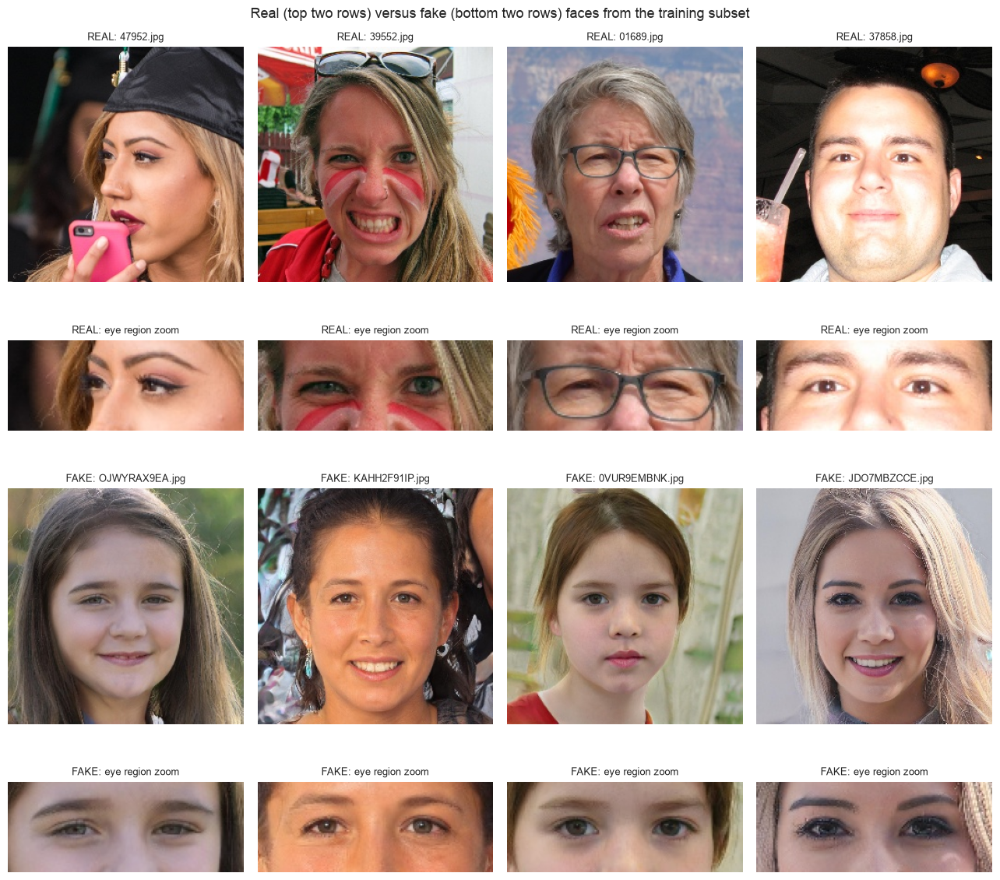

In [17]:
# Four real and four fake training faces, each with a zoom of the eye region at full resolution
fig, axes = plt.subplots(4, 4, figsize=(13, 12.5))
for r, label in enumerate(classes):
    picks = subset_df[(subset_df["subset_split"] == "train") & (subset_df["label"] == label)].sample(4, random_state=seed)
    for c, (_, row) in enumerate(picks.iterrows()):
        face = np.array(Image.open(row["subset_path"]))
        axes[2 * r, c].imshow(face)
        axes[2 * r, c].set_title(f"{label.upper()}: {row['file']}", fontsize=9)
        axes[2 * r + 1, c].imshow(face[90:150, 50:206])   # the eye region, not resized
        axes[2 * r + 1, c].set_title(f"{label.upper()}: eye region zoom", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Real (top two rows) versus fake (bottom two rows) faces from the training subset", fontsize=13)
plt.tight_layout()
save_fig("05_real_versus_fake_samples.png")
plt.show()

This code shows four real and four fake faces from the training subset, and under each face a zoomed crop of the eye region taken from the full 256 by 256 image without any resizing. The zoom is there because the clues that give a StyleGAN face away tend to be small, such as odd textures in the hair, mismatched earrings, strange backgrounds or slightly blurred details around the eyes and teeth. Comparing the zooms side by side shows how much of that detail survives in the image, which feeds straight into the choice of input size in 4.6. The chart is saved as `figures/05_real_versus_fake_samples.png`.

**What the output shows.** The real faces show the messiness of real photographs: a phone, face paint, glasses and strong flash lighting. The fake faces look clean and evenly lit, with smooth skin, and their eye regions look slightly softer and smoother than the real ones, although the difference is small enough that it is hard to name for a single image. **What this means for training:** the clues that separate the classes are small textures and fine details rather than the overall look of the face, so the input size and the augmentation must not destroy fine detail. Both of these are tested in 4.6 and 5.2.

#### 4.4.4 Brightness and Contrast

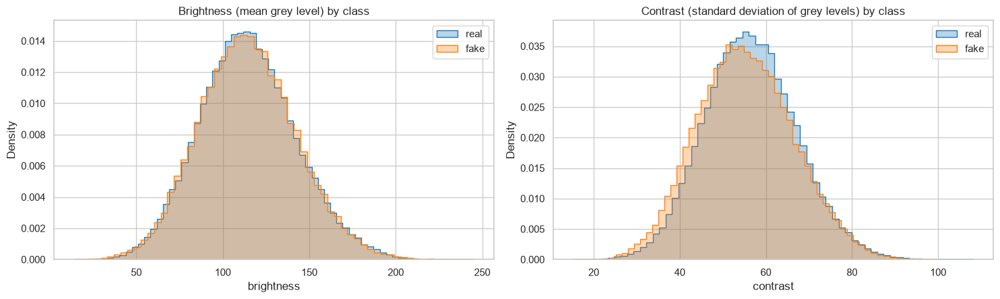

      brightness                contrast              
            mean  median    std     mean median    std
label                                                 
fake      114.42  113.60  27.98    55.23  54.86  11.15
real      114.48  113.55  27.79    56.41  56.14  10.65


In [18]:
# Brightness and contrast distributions by class (measured in 4.2 on all 140,000 images)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, column, title in [(axes[0], "brightness", "Brightness (mean grey level)"),
                          (axes[1], "contrast", "Contrast (standard deviation of grey levels)")]:
    for label in classes:
        sns.histplot(full_df.loc[full_df["label"] == label, column], ax=ax, label=label, bins=60,
                     stat="density", element="step", color=colours[label], alpha=0.3)
    ax.set_title(title + " by class")
    ax.legend()
plt.tight_layout()
save_fig("06_brightness_and_contrast.png")
plt.show()
print(full_df.groupby("label")[["brightness", "contrast"]].agg(["mean", "median", "std"]).round(2))

This code compares how bright and how contrasted the real and fake faces are, using the values measured for every image in 4.2. Each class is drawn as a histogram scaled to a density (the share of images in each bar), so the two classes can be laid on top of each other, and the table underneath gives the mean, median and spread for each class. This matters for training in two ways. If one class were clearly brighter or darker, the CNN could separate the classes by overall lighting instead of by the face itself, and the spread of brightness shows whether augmentation needs to add lighting changes.

**What the output shows.** The histograms of the two classes lie almost exactly on top of each other. Average brightness is 114.48 for real and 114.42 for fake faces, and average contrast is 56.41 for real and 55.23 for fake faces, with a very similar spread in both. Both classes cover a wide range of lighting, from very dark to very bright. **What this means for training:** the CNN cannot separate the classes by overall lighting, so it has to learn from the faces themselves, and because lighting already varies widely in both classes there is no need to add brightness augmentation.

#### 4.4.5 Colour Channels

In [19]:
# Load a sample of training images at full size for the colour and average face analysis
eda_per_class = 1000   # 1,000 images per class give stable averages and fit easily in memory

eda_arrays = {}
for label in classes:
    paths = subset_df[(subset_df["subset_split"] == "train") & (subset_df["label"] == label)]["subset_path"]
    paths = paths.sample(eda_per_class, random_state=seed)
    eda_arrays[label] = np.stack([np.asarray(Image.open(p).convert("RGB")) for p in paths])
    print(f"{label}: array of shape {eda_arrays[label].shape}, {eda_arrays[label].nbytes / 1e6:.0f} MB")

real: array of shape (1000, 256, 256, 3), 197 MB


fake: array of shape (1000, 256, 256, 3), 197 MB


This code loads a random sample of training images into memory as arrays for the next two analyses. The sample size is set here: 1,000 images per class is enough for the averages to be stable, and at full size it uses only a few hundred megabytes, which is safe on a 16 GB laptop. Each class becomes one four dimensional array with the shape number of images by height by width by channels, which is the batch shape a CNN uses, as explained in ICE Task 4. The images are kept at their full 256 by 256 size here so that no detail is lost before the colours and the average faces are studied.

**What the output shows.** Each class is now a single array of shape (1000, 256, 256, 3), which uses 197 MB of memory per class. This is comfortably small on a 16 GB laptop.

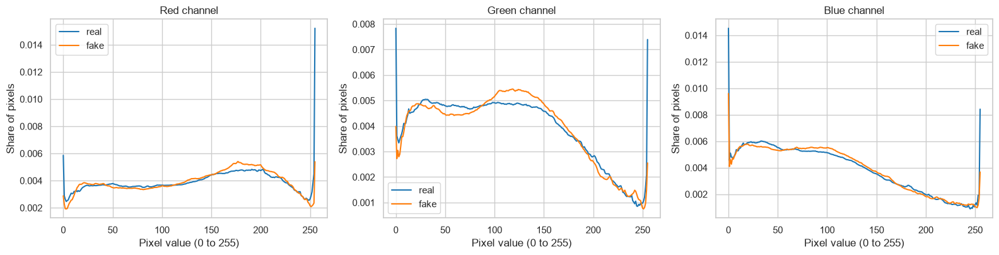

       Blue  Green     Red
fake  97.76  109.3  133.19
real  96.96  108.4  132.79


In [20]:
# Red, green and blue histograms by class
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
channel_means = {}
for i, (ax, channel) in enumerate(zip(axes, ["Red", "Green", "Blue"])):
    for label in classes:
        values = eda_arrays[label][..., i].ravel()
        counts = np.bincount(values, minlength=256)
        ax.plot(counts / counts.sum(), color=colours[label], label=label)
        channel_means[(label, channel)] = values.mean()
    ax.set_title(f"{channel} channel")
    ax.set_xlabel("Pixel value (0 to 255)")
    ax.set_ylabel("Share of pixels")
    ax.legend()
plt.tight_layout()
save_fig("07_colour_channels.png")
plt.show()
print(pd.Series(channel_means).unstack().round(2))

This code counts how often each pixel value from 0 to 255 appears in the red, green and blue channels, separately for real and fake faces, and draws the three histograms as lines that can be compared directly. The counts are turned into shares so the two classes are on the same scale, and the table below gives the average value of each channel per class. Colour is worth studying because a generator can leave small but systematic traces in colour, and the result decides whether the model should keep all three colour channels or could work in grey. The chart is saved as `figures/07_colour_channels.png`.

**What the output shows.** The average colour values are almost the same for both classes: red 132.79 for real and 133.19 for fake, green 108.40 and 109.30, and blue 96.96 and 97.76, a difference of under one point out of 255. The curves have the same shape too. The main difference is at the very ends: real photos have much taller spikes at 0 and 255, which are pixels that are completely black or completely saturated. This is typical of a real camera that cannot capture very dark or very bright areas, while the fake faces have fewer of these clipped pixels and a slightly higher bump of middle green and red values. **What this means for training:** colour does carry small differences between the classes, such as the clipping at the extremes, so the model keeps all three colour channels.

#### 4.4.6 Average Faces

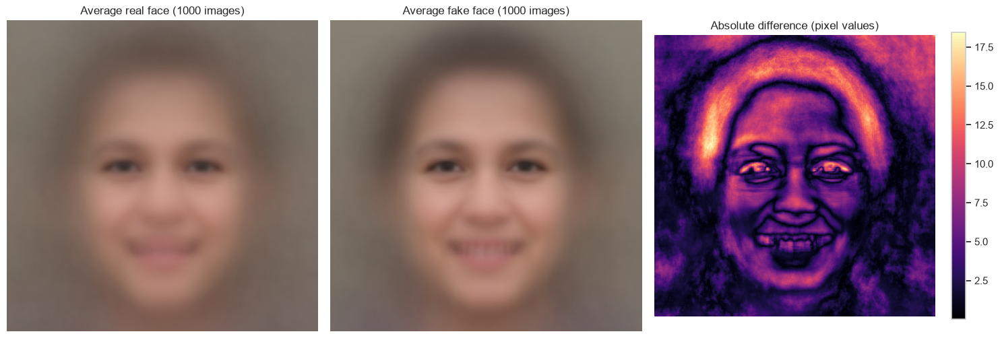

Mean difference: 4.61   largest difference: 18.44   (out of 255)


In [21]:
# The average image of each class and the difference between them
mean_faces = {label: eda_arrays[label].mean(axis=0, dtype=np.float64) for label in classes}
difference = np.abs(mean_faces["real"] - mean_faces["fake"]).mean(axis=2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(mean_faces["real"].astype("uint8"))
axes[0].set_title(f"Average real face ({eda_per_class} images)")
axes[1].imshow(mean_faces["fake"].astype("uint8"))
axes[1].set_title(f"Average fake face ({eda_per_class} images)")
shown = axes[2].imshow(difference, cmap="magma")
axes[2].set_title("Absolute difference (pixel values)")
plt.colorbar(shown, ax=axes[2], fraction=0.046)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
save_fig("08_average_faces.png")
plt.show()
print(f"Mean difference: {difference.mean():.2f}   largest difference: {difference.max():.2f}   (out of 255)")

This code adds up the 1,000 sampled faces of each class pixel by pixel and divides by 1,000, which gives the average real face and the average fake face. It then measures the absolute difference between the two averages at every pixel and shows it as a heat map, where brighter colours mean a bigger difference. Average faces show the parts of the image that are the same in almost every photo, such as where the eyes and mouth sit, and the difference map shows where the two classes differ on average. This tells us whether the faces are lined up in the same way in both classes and whether any region, for example the background or the edges, differs systematically. The chart is saved as `figures/08_average_faces.png`.

**What the output shows.** Both average faces are blurry faces in the same position, with the eyes, nose and mouth in the same places. This shows that both classes are aligned in the same way, so the position of the face gives no clue. The mean difference between the two averages is only 4.61 out of 255, and the largest is 18.44. The difference map is brightest in a band around the top of the head and the hair, and around the eyes and the teeth, which suggests that the fakes differ most in hair, eyes and smiles rather than in the background. **What this means for training:** there is no large global difference that a model could use as a shortcut, so the CNN must learn local details. Its convolution filters, which look at small regions, suit this well.

### 4.5 Shortcut Checks

A CNN learns whatever separates the classes most easily, even if it has nothing to do with the face. If, for example, every fake image had a smaller file or a darker background, the model could score very well by learning that shortcut and would then fail on new images that do not share it. This section compares real and fake images on properties that have nothing to do with the face and tests how far a simple rule based on one of them could get.

In [22]:
# Compare real and fake images on properties that have nothing to do with the face
measures = {"size_kb": "File size (KB)", "width": "Width (pixels)", "height": "Height (pixels)",
            "brightness": "Brightness", "contrast": "Contrast"}
rows = []
for column, name in measures.items():
    real = full_df.loc[full_df["label"] == "real", column]
    fake = full_df.loc[full_df["label"] == "fake", column]
    pooled_sd = np.sqrt((real.var() + fake.var()) / 2)
    effect = (real.mean() - fake.mean()) / pooled_sd if pooled_sd > 0 else 0.0
    rows.append([name, real.mean(), fake.mean(), real.median(), fake.median(), effect])
shortcut_table = pd.DataFrame(rows, columns=["Measure", "Real mean", "Fake mean", "Real median",
                                             "Fake median", "Difference in standard deviations"]).round(3)
shortcut_table.to_csv(out_dir / "06_shortcut_checks.csv", index=False)
shortcut_table

,Measure,Real mean,Fake mean,Real median,Fake median,Difference in standard deviations
0,File size (KB),28.260,27.760,28.052,27.335,0.129
1,Width (pixels),256.000,256.000,256.000,256.000,0.000
2,Height (pixels),256.000,256.000,256.000,256.000,0.000
3,Brightness,114.484,114.423,113.554,113.596,0.002
4,Contrast,56.414,55.231,56.141,54.859,0.109


This code compares the real and fake images on five properties that say nothing about whether a face is genuine: file size, width, height, brightness and contrast. For each one it gives the mean and median of both classes and a standardised difference, which is the gap between the two means divided by their pooled standard deviation. A standardised difference near zero means the two classes overlap almost completely, while a large value means the property alone would separate a lot of the images. The table is saved as `outputs/06_shortcut_checks.csv`.

**What the output shows.** The two classes are almost identical on every property. Width and height are exactly 256 for both, so their difference is 0. Brightness differs by only 0.002 standard deviations. File size (28.26 KB for real against 27.76 KB for fake, a difference of 0.129 standard deviations) and contrast (56.41 against 55.23, 0.109 standard deviations) show small differences. With differences this small, the two classes overlap almost completely on every property.

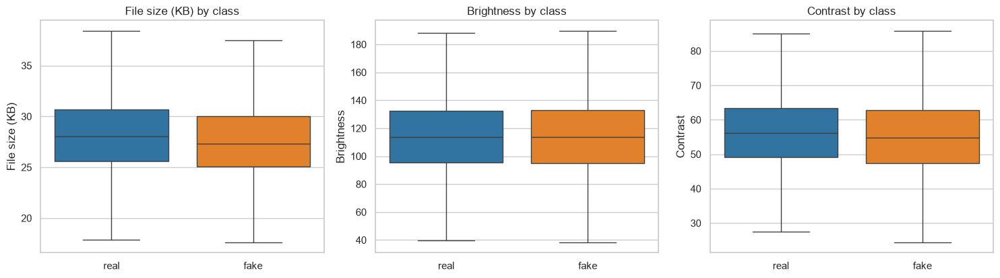

In [23]:
# Box plots of the same properties by class
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, column in zip(axes, ["size_kb", "brightness", "contrast"]):
    sns.boxplot(data=full_df, x="label", y=column, hue="label", order=classes, hue_order=classes,
                palette=colours, showfliers=False, ax=ax, legend=False)
    ax.set_title(f"{measures[column]} by class")
    ax.set_xlabel("")
    ax.set_ylabel(measures[column])
plt.tight_layout()
save_fig("09_shortcut_boxplots.png")
plt.show()

This code draws box plots of file size, brightness and contrast for each class. The box covers the middle half of the images, the line inside it is the median and the whiskers show the usual range, with extreme values hidden so the boxes stay readable. Width and height are left out because the previous checks showed whether they vary at all. Box plots make it easy to see whether the boxes of the two classes overlap, which is the visual version of the standardised difference in the table. The chart is saved as `figures/09_shortcut_boxplots.png`.

**What the output shows.** The boxes of the two classes overlap almost completely for all three properties. The fake file size box sits only slightly lower than the real one, and the brightness and contrast boxes are practically the same. This confirms visually that none of these properties separates real from fake faces.

In [24]:
# How accurate would a single cut off rule be? It is fitted on train and tested on valid.
def best_rule(column):
    train, valid = full_df[full_df["split"] == "train"], full_df[full_df["split"] == "valid"]
    best = (0.0, None, None)
    for cut in np.percentile(train[column], np.arange(1, 100)):
        for fake_if_below in [True, False]:
            guess_fake = train[column] < cut if fake_if_below else train[column] >= cut
            acc = (guess_fake == (train["label"] == "fake")).mean()
            if acc > best[0]:
                best = (acc, cut, fake_if_below)
    acc, cut, below = best
    guess_fake = valid[column] < cut if below else valid[column] >= cut
    rule = f"fake if {measures[column]} is {'below' if below else 'at least'} {cut:.2f}"
    return [measures[column], rule, round(acc, 4), round((guess_fake == (valid["label"] == "fake")).mean(), 4)]

rules = pd.DataFrame([best_rule(c) for c in ["size_kb", "brightness", "contrast"]],
                     columns=["Measure", "Best rule found on the training split", "Train accuracy", "Validation accuracy"])
rules.to_csv(out_dir / "07_shortcut_rules.csv", index=False)
rules

,Measure,Best rule found on the training split,Train accuracy,Validation accuracy
0,File size (KB),fake if File size (KB) is below 28.27,0.5372,0.5396
1,Brightness,fake if Brightness is below 80.73,0.5023,0.4990
2,Contrast,fake if Contrast is below 51.57,0.5263,0.5307


This code tests how far a lazy model could get by looking at one simple property. For file size, brightness and contrast it tries 99 cut off values (every percentile of the training split) in both directions, for example calling an image fake when its file is smaller than the cut off, and keeps the rule that is most accurate on the 100,000 training images. It then applies that same rule to the 20,000 validation images, which it has not seen, to get an honest accuracy. Random guessing scores 50 percent on these balanced classes, so a rule that scores far above 50 percent would be a shortcut the CNN could exploit instead of learning about faces. The results are saved as `outputs/07_shortcut_rules.csv`.

**What the output shows.** The best possible single rule is weak. Calling an image fake when its file is smaller than 28.27 KB scores 53.72 percent on the training split and 53.96 percent on the validation split, only about 4 points better than guessing. The best contrast rule scores 53.07 percent on validation and the best brightness rule 49.90 percent, which is no better than a coin toss. **Conclusion of the shortcut checks:** no strong shortcut was found. File size and contrast hold a very small signal (about 4 and 3 points above guessing), possibly because the two classes went through slightly different processing before they were saved as JPEGs, but it is far too weak to explain a good result. So any accuracy the CNN reaches well above about 54 percent must come from what it learns about the faces.

### 4.6 Feature Selection

In a table of numbers, feature selection means choosing which columns to keep, for example with p values. A CNN is different, because its convolution layers learn their own features straight from the pixels (GeeksforGeeks, 2026e). The feature decisions for a CNN are therefore about the input: how large the images are, whether colour is kept, how the pixel values are scaled and which augmentation is used. Each decision below is justified from the EDA.

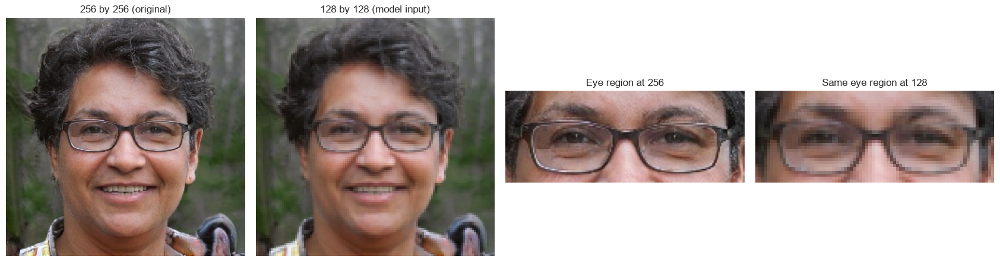

Pixels per image at 256: 196608   at 128: 49152   ratio: 4


In [25]:
# One fake face at 256 by 256 and at 128 by 128, with the same eye region zoomed in
example = subset_df[(subset_df["subset_split"] == "train") & (subset_df["label"] == "fake")].iloc[0]
full_size = Image.open(example["subset_path"])
half_size = full_size.resize((128, 128), Image.BILINEAR)

fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
panels = [(full_size, "256 by 256 (original)"), (half_size, "128 by 128 (model input)"),
          (np.array(full_size)[90:150, 50:206], "Eye region at 256"),
          (np.array(half_size)[45:75, 25:103], "Same eye region at 128")]
for ax, (picture, title) in zip(axes, panels):
    ax.imshow(picture)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
save_fig("10_resolution_128_vs_256.png")
plt.show()
print("Pixels per image at 256:", 256 * 256 * 3, "  at 128:", 128 * 128 * 3, "  ratio:", (256 * 256) // (128 * 128))

This code shows one fake face at its original size of 256 by 256 and at 128 by 128, together with the same eye region from both versions. It also prints how many values each image holds at each size. The question is whether halving the width and height loses the details the model needs.

**Image size.** The images are resized to 128 by 128. At this size each image holds four times fewer values, so training is about four times lighter, the cached images fit easily in memory and several models can be compared within the time budget. The EDA in 4.4.2 showed that every image is already a square of the same size, so resizing to another square only scales the image and never stretches or crops a face. The zoomed eye region shows how much fine detail remains at 128, which is the price paid for speed; this is noted as a limitation.

**What the output shows.** Each image holds 196,608 values at 256 by 256 and 49,152 at 128 by 128, four times fewer. At full size, the overall face looks almost the same at 128. In the zoomed eye region, however, the 128 version is clearly blockier: single hairs, eyelashes, the thin frame of the glasses and skin texture become blurred. This confirms that 128 by 128 is a trade off, and it is recorded as a limitation. A larger input might help the model see the finest artefacts, but it would make every experiment about four times slower.

In [26]:
# Pixel values before and after the Rescaling(1./255) layer used in the model
pixels = np.array(half_size, dtype=np.float32)
scaled = layers.Rescaling(1./255)(pixels[np.newaxis, ...]).numpy()   # np.newaxis adds the batch dimension
print("Before scaling: shape", pixels.shape, " min", pixels.min(), " max", pixels.max())
print("After scaling : shape", scaled.shape, " min", scaled.min(), " max", round(float(scaled.max()), 3))

Before scaling: shape (128, 128, 3)  min 9.0  max 250.0
After scaling : shape (1, 128, 128, 3)  min 0.03529412  max 0.98


This code shows what the `Rescaling(1./255)` layer from the class notebook does to one image. It adds the batch dimension at the front, as in ICE Task 4, and divides every pixel by 255 so the values run from 0 to 1 instead of 0 to 255.

**Keeping colour.** The images keep all three colour channels (RGB). The colour histograms in 4.4.5 showed whether the real and fake faces differ in colour, and a CNN can use colour traces that would disappear in grey, while the extra cost of colour is small because it only affects the first convolution layer.

**Scaling pixels to 0 to 1.** Neural networks learn more smoothly when their inputs are small numbers on a similar scale, because large raw values lead to large weight updates. Putting the rescaling inside the model also means every image is scaled the same way during training, testing and later use, so it can never be forgotten.

**What the output shows.** Before scaling, the resized image is a (128, 128, 3) array with values from 9.0 to 250.0. After `Rescaling(1./255)` it has the batch shape (1, 128, 128, 3) and values from about 0.035 to 0.98. The relative differences between pixels are kept exactly; only the scale changes.

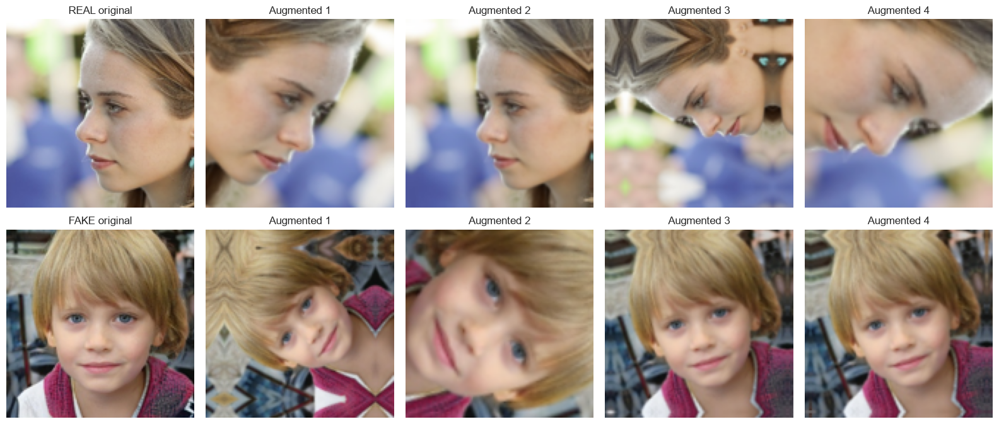

In [27]:
# Augmentation options, and a preview of the class augmentation
def make_augmentation(kind):
    # "class" copies the augmentation of the class model in CNN_Sept_24.ipynb
    if kind == "class":
        return tf.keras.Sequential([layers.RandomFlip("horizontal", seed=seed),
                                    layers.RandomRotation(0.2, seed=seed),
                                    layers.RandomZoom(0.3, seed=seed)], name="class_augmentation")
    if kind == "flip":
        return tf.keras.Sequential([layers.RandomFlip("horizontal", seed=seed)], name="flip_augmentation")
    return None   # "none" means no augmentation

preview = make_augmentation("class")
picks = [subset_df[(subset_df["subset_split"] == "train") & (subset_df["label"] == l)].iloc[1] for l in classes]
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for r, row in enumerate(picks):
    face = np.array(Image.open(row["subset_path"]).resize((128, 128)), dtype=np.float32)
    axes[r, 0].imshow(face.astype("uint8"))
    axes[r, 0].set_title(f"{row['label'].upper()} original")
    for c in range(1, 5):
        augmented = preview(face[np.newaxis, ...], training=True)[0].numpy()
        axes[r, c].imshow(np.clip(augmented, 0, 255).astype("uint8"))
        axes[r, c].set_title(f"Augmented {c}")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
save_fig("11_augmentation_preview.png")
plt.show()

This code defines the augmentation options that the experiments choose from and previews the class augmentation. Augmentation makes small random changes to each training image every time it is seen, which adds variety without collecting new data (GeeksforGeeks, 2023). The `class` option copies the class model in `CNN_Sept_24.ipynb`: a random horizontal flip, a random rotation of up to 20 percent of a full turn either way and a random zoom of up to 30 percent. The `flip` option keeps only the horizontal flip, and `none` uses no augmentation. Each random layer gets the seed so the changes can be repeated. The preview shows one real and one fake face next to four augmented versions of each.

**Choice of augmentation.** The baseline uses the class augmentation, as asked by the brief to start from the class model. A horizontal flip is a safe change because a mirrored face is still a real or fake face. Rotation and zoom are less certain for this task: they resample the pixels and fill the corners, which may blur the fine textures that separate real from fake faces. Experiment 2 in 5.2.2 tests this directly instead of guessing.

**Class weights.** Class weights are only needed when one class is much larger than the other. The EDA in 4.4.1 showed that the subset is exactly balanced, with 5,000 real and 5,000 fake training images, so class weights are not needed and the plain loss treats both classes equally.

**Looking inside the model.** Once the models have been trained, the feature maps of the first convolution layer of the chosen model are plotted for one real and one fake face in 5.5.1, which shows what the CNN actually looks at.

**What the output shows.** The preview shows that the flip only mirrors the face, while rotation and zoom change it a lot. Several augmented images are tilted and enlarged, and their empty corners are filled with mirrored copies of the image, which creates strange kaleidoscope patterns in the background. The zoomed versions are also visibly softer, because their pixels are stretched. This supports the worry that the class augmentation may hide or invent the fine textures that separate real from fake faces, and Experiment 2 tests it.

### 4.7 Train, Validation and Test Split

The working subset already has three separate folders, so the split is fixed by the folders and no image can appear in two sets (this was proven in 4.3). The training set is used to learn the weights, the validation set is used to compare models and choose the best one, and the test set is used only once at the very end, so its score is an honest estimate of how the chosen model will do on new faces.

This also fixes one of the two faults in the class notebook `CNN_Sept_24.ipynb`. That notebook built its training set with `petImages.take(train_size)` and its validation set with `petImages.take(val_size)`. Both calls start from the beginning of the same dataset, so every validation batch was also a training batch, and because the dataset is reshuffled on every pass the split also changed from epoch to epoch. The validation score therefore measured images the model had already trained on. Using separate folders removes this overlap completely.

In [28]:
img_size = 128
batch_size = 32
class_order = ["real", "fake"]   # real = 0 and fake = 1, so the sigmoid output is the chance that a face is fake

def load_split(split):
    # Loading as in CNN_Sept_24.ipynb and Ice Task 1, with labels taken from the folder names
    return tf.keras.utils.image_dataset_from_directory(
        subset_dir / split, labels="inferred", label_mode="binary", class_names=class_order,
        image_size=(img_size, img_size), batch_size=batch_size, shuffle=(split == "train"), seed=seed)

train_raw = load_split("train")
val_raw = load_split("val")
test_raw = load_split("test")
print("Class names:", train_raw.class_names)
for images, labels in train_raw.take(1):
    print("Image batch shape:", images.shape, "  label batch shape:", labels.shape)
    print("Pixel range before rescaling:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

Found 10000 files belonging to 2 classes.


Found 2000 files belonging to 2 classes.


Found 2000 files belonging to 2 classes.


Class names: ['real', 'fake']
Image batch shape: (32, 128, 128, 3)   label batch shape: (32, 1)
Pixel range before rescaling: 0.0 to 255.0


This code sets the two main input settings and loads the three folders with `image_dataset_from_directory`, the loader from the. `img_size = 128` is the input size chosen in 4.6, and `batch_size = 32` is the number of images the model looks at before each weight update, the same as in class. The labels are inferred from the folder names. The class order is set to real then fake, so real is 0, fake is 1 and the single sigmoid output of the model is the probability that a face is fake. This makes fake the positive class, which suits the security purpose: recall then measures how many fakes are caught and precision measures how often a fake alarm is correct. Only the training set is shuffled (with the seed); the validation and test sets keep a fixed order so that predictions can be matched back to their files. The code prints the class names, the shape of one batch of images and labels, and the pixel range before rescaling.

**What the output shows.** The loader found 10,000 training files, 2,000 validation files and 2,000 test files, each belonging to the two classes. The class names come out as ['real', 'fake'], so real is 0 and fake is 1. One batch holds 32 images of shape 128 by 128 by 3, giving a batch shape of (32, 128, 128, 3), and the labels have the shape (32, 1), one label per image. The pixel values still run from 0 to 255, because the scaling to 0 to 1 is done by the `Rescaling` layer inside the model.

In [29]:
# Caching and prefetching. Pattern from the TensorFlow image classification tutorial (TensorFlow, 2026),
# changed to cache single images so that the batch size can be changed in 5.2.3. Written with help from Claude (Anthropic, 2026).
autotune = tf.data.AUTOTUNE
train_images = len(train_raw.file_paths)
train_cache = train_raw.unbatch().apply(tf.data.experimental.assert_cardinality(train_images)).cache()

def make_train(batch_size):
    # Reshuffle the cached training images every epoch, then group them into batches
    return train_cache.shuffle(2000, seed=seed).batch(batch_size).prefetch(autotune)

train_ds = make_train(batch_size)
val_ds = val_raw.cache().prefetch(autotune)
test_ds = test_raw.cache().prefetch(autotune)
print("Training batches per epoch at batch size 32:", len(train_raw))
print("Validation batches:", len(val_raw), "  test batches:", len(test_raw))

Training batches per epoch at batch size 32: 313
Validation batches: 63   test batches: 63


This code makes the data pipeline fast. Caching keeps the decoded and resized images in memory after the first epoch, so the JPEG files are not read and decoded again on every epoch, and prefetching prepares the next batch while the GPU is still working on the current one (TensorFlow, 2026). The training images are cached one by one instead of in batches, so the small `make_train` function can reshuffle them every epoch and group them into any batch size, which the learning rate and batch size experiment in 5.2.3 needs. The number of training images is attached to the pipeline with `assert_cardinality`, so Keras knows how many batches make up one epoch. Because `make_train` already shuffles, `model.fit` is later told not to shuffle again. The validation and test sets are cached in their fixed order. The code prints how many batches each set has.

**What the output shows.** At a batch size of 32, one training epoch has 313 batches (10,000 divided by 32, rounded up), and the validation and test sets have 63 batches each. In training this pipeline kept every epoch at about 8 to 15 seconds on the M4 GPU.

### 4.8 Building the CNN

The class model went straight from the last pooling layer to the `Dense` layers without a `Flatten` layer. A `Dense` layer works on the last dimension of whatever it receives, so without flattening it was applied separately at every position of the 4D feature maps and produced a grid of predictions instead of one prediction per image. The `Flatten` layer turns the feature maps into one long vector per image, so the dense layers make a single real or fake decision for the whole face.

In [30]:
model_settings = {}   # a short description of every model, used in the comparison table

def build_model(augmentation="class", dropout=0.0, extra_block=False, learning_rate=0.001, name="model"):
    # Layers adapted from the class model in CNN_Sept_24.ipynb, with the missing Flatten layer added.
    # The options for augmentation, dropout, extra block and learning rate were written with help from Claude (Anthropic, 2026).
    tf.keras.utils.set_random_seed(seed)   # every model starts from the same random state
    model = tf.keras.Sequential(name=name)
    model.add(tf.keras.Input(shape=(img_size, img_size, 3)))
    if augmentation != "none":
        model.add(make_augmentation(augmentation))
    model.add(layers.Rescaling(1./255))
    for filters in [32, 64, 128]:
        model.add(layers.Conv2D(filters, (3, 3), activation="relu"))
        model.add(layers.MaxPooling2D())
    if extra_block:
        model.add(layers.Conv2D(256, (3, 3), activation="relu"))
        model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D())
    model.add(layers.Flatten())
    if dropout > 0:
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(128, activation="relu"))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="binary_crossentropy", metrics=["accuracy"])
    model_settings[name] = {"augmentation": augmentation, "dropout": dropout,
                            "extra_block": extra_block, "learning_rate": learning_rate}
    return model

This code writes one reusable function, `build_model`, that builds every CNN in this notebook, so the only differences between models are the ones chosen on purpose. With its default settings it builds the class model exactly, plus the missing `Flatten` layer. The options switch on the changes tested in the experiments: the kind of augmentation, a dropout layer before the dense layer, an extra convolution block with batch normalisation, and the learning rate. The seed is reset at the start, so every model starts from the same random state and differences between models come from the settings and not from luck. The model is compiled with the `adam` optimiser and the `binary_crossentropy` loss, which is the standard loss for a yes or no output, and accuracy is tracked during training. The settings of every model are stored in `model_settings` for the comparison table in 5.3.

**What the output shows.** The cell prints nothing because it only defines the function. The models it builds are shown in the next cell and in the comparison table in 5.3.

In [31]:
baseline = build_model(augmentation="class", name="baseline")
baseline.summary()

Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ class_augmentation (Sequential) │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

This code builds the baseline model and prints its summary, which lists every layer, the shape of its output and how many weights it learns. In plain English, the layers do the following (GeeksforGeeks, 2026e).

1. The augmentation block makes random flips, rotations and zooms of each training image, and does nothing when the model is used for prediction.
2. `Rescaling(1./255)` turns pixel values from 0 to 255 into 0 to 1.
3. The first `Conv2D` layer slides 32 small 3 by 3 filters over the image. Each filter learns to respond to a simple pattern such as an edge, a colour change or a texture, and produces one feature map. ReLU then keeps positive responses and sets negative ones to zero. As my Ice Task 2 showed, ReLU learns faster than sigmoid and tanh in hidden layers because its gradient does not shrink towards zero for positive values (GeeksforGeeks, 2026a).
4. Each `MaxPooling2D` layer keeps the largest value in every 2 by 2 square, which halves the width and height, keeps the strongest responses and makes the model less sensitive to small shifts (GeeksforGeeks, 2026f).
5. The second and third `Conv2D` layers use 64 and 128 filters. Because they work on the feature maps of the layer before, they can combine simple patterns into more complex ones such as parts of an eye or the texture of skin and hair.
6. `Flatten` turns the final feature maps into one long vector per image.
7. `Dense(128, relu)` is a fully connected layer that combines all the features into 128 higher level signals.
8. `Dense(1, sigmoid)` is the output. Sigmoid squeezes any number into the range 0 to 1, which is read as the probability that the face is fake. As in Ice Task 2, sigmoid suits a single yes or no output, while softmax would be used for more than two classes.

**What the output shows.** The summary shows how the image shrinks as it passes through the network. The input of 128 by 128 by 3 becomes 126 by 126 by 32 after the first convolution (a 3 by 3 filter cannot be centred on the outermost pixels, so one pixel is lost on each side), then 63 by 63 after pooling, 61 by 61 by 64, 30 by 30, 28 by 28 by 128 and finally 14 by 14 by 128. `Flatten` turns this into a vector of 25,088 values. The model has 3,304,769 trainable parameters, and 3,211,392 of them, about 97 percent, sit in the `Dense(128)` layer that follows `Flatten`. The three convolution layers together have only 93,248 parameters (896, 18,496 and 73,856). This shows that the dense layer is where the model has the most freedom to memorise, which is why dropout is placed in front of it in Experiment 1.

In [32]:
def train_model(model, epochs, batch_size=32, early_stop=True):
    # Timing idea from Ice Task 3 and early stopping from the Class 11 Sep notebook
    stopper = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    start = time.time()
    history = model.fit(make_train(batch_size), validation_data=val_ds, epochs=epochs,
                        callbacks=[stopper] if early_stop else [], shuffle=False, verbose=2)
    seconds = time.time() - start
    if early_stop and stopper.best_weights is not None:
        model.set_weights(stopper.best_weights)   # make sure the best epoch is kept even if training never stopped early
    hist = pd.DataFrame(history.history)
    hist["epoch"] = np.arange(1, len(hist) + 1)
    best = int(hist["val_loss"].idxmin())
    record = {"model": model.name, "parameters": model.count_params(), "batch_size": batch_size,
              "epochs_run": len(hist), "best_epoch": best + 1,
              "weights_from_epoch": best + 1 if early_stop else len(hist),
              "train_time_s": round(seconds, 1), "time_per_epoch_s": round(seconds / len(hist), 1),
              "train_acc_at_best": hist.loc[best, "accuracy"], "val_acc_at_best": hist.loc[best, "val_accuracy"]}
    record["overfit_gap"] = record["train_acc_at_best"] - record["val_acc_at_best"]
    return hist, record

This code writes the second reusable function, `train_model`, so that every model is trained and recorded in exactly the same way. It trains the model on the training set, checks it on the validation set after every epoch and times the whole run, the way Ice Task 3 timed its runs. When early stopping is switched on, it watches the validation loss and stops once the loss has not improved for three epochs in a row, then puts back the weights from the best epoch, as in the Class 11 Sep notebook (GeeksforGeeks, 2026g). The extra `set_weights` line makes sure the best weights are also kept when a run reaches its epoch limit without stopping early. The function returns the history of every epoch as a table and a record with the number of parameters, the batch size, the number of epochs run, the best epoch, which epoch's weights are kept, the training time, the time per epoch, and the training and validation accuracy at the best epoch. The gap between those two accuracies is the overfitting check from Ice Task 3: a large gap means the model does much better on images it has seen than on new ones.

**What the output shows.** The cell prints nothing because it only defines the training function, which every model from 5.1 onwards uses.

### 5.1 Baseline Model Results

The baseline is trained for a fixed 10 epochs without early stopping, so any overfitting is left visible in the curves instead of being hidden.

In [33]:
baseline_hist, baseline_record = train_model(baseline, epochs=10, early_stop=False)
pd.Series(baseline_record)

Epoch 1/10


313/313 - 14s - 45ms/step - accuracy: 0.5138 - loss: 0.6979 - val_accuracy: 0.5175 - val_loss: 0.6917


Epoch 2/10


313/313 - 12s - 39ms/step - accuracy: 0.5456 - loss: 0.6939 - val_accuracy: 0.5385 - val_loss: 0.6871


Epoch 3/10


313/313 - 12s - 39ms/step - accuracy: 0.5368 - loss: 0.8041 - val_accuracy: 0.5080 - val_loss: 2.7293


... (11 outputs left out)

313/313 - 12s - 39ms/step - accuracy: 0.5347 - loss: 56.6051 - val_accuracy: 0.5375 - val_loss: 43.4969


Epoch 10/10


313/313 - 12s - 39ms/step - accuracy: 0.5306 - loss: 169.4768 - val_accuracy: 0.5000 - val_loss: 314.1886


model                 baseline
parameters             3304769
batch_size                  32
epochs_run                  10
best_epoch                   2
weights_from_epoch          10
train_time_s             125.0
time_per_epoch_s          12.5
train_acc_at_best       0.5456
val_acc_at_best         0.5385
overfit_gap             0.0071
dtype: object

This code trains the baseline for 10 epochs with early stopping switched off. For every epoch Keras prints the training loss and accuracy and the validation loss and accuracy, and the record at the end summarises the run.

**What the output shows.** The baseline trained for 10 epochs in 125.0 seconds, about 12.5 seconds per epoch. The run did not go well. The validation loss was lowest at epoch 2 (0.6871), and from epoch 3 the loss started to explode: the training loss rose to 16.9 at epoch 5 and 169.5 at epoch 10, and the validation loss reached 314.2. Training accuracy never rose above 0.555, so the model hardly learned anything. The record shows the best epoch was 2, but because early stopping was off, the weights kept are those from epoch 10, the worst one. The overfitting gap at the best epoch is only 0.007, so this is not classic overfitting but a failure to learn.

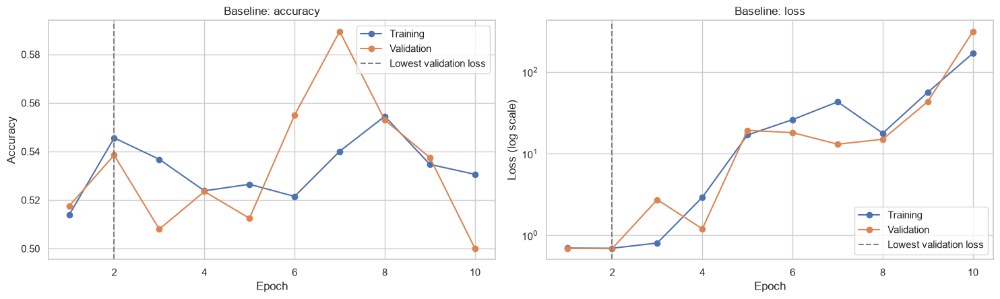

In [34]:
def plot_history(hist, title, file_name):
    # Accuracy and loss curves, as in my Part 1 notebook
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        ax.plot(hist["epoch"], hist[metric], marker="o", label="Training")
        ax.plot(hist["epoch"], hist["val_" + metric], marker="o", label="Validation")
        ax.axvline(hist.loc[hist["val_loss"].idxmin(), "epoch"], color="grey", linestyle="--",
                   label="Lowest validation loss")
        ax.set_title(f"{title}: {metric}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(metric.title() + (" (log scale)" if metric == "loss" else ""))
        if metric == "loss":
            ax.set_yscale("log")   # keeps small losses readable when a run blows up
        ax.legend()
    plt.tight_layout()
    save_fig(file_name)
    plt.show()

plot_history(baseline_hist, "Baseline", "12_baseline_curves.png")

This code writes a small function that draws the training and validation accuracy and loss for every epoch, with a dashed line at the epoch with the lowest validation loss, and uses it on the baseline. The loss is drawn on a log scale, where each step up the axis is ten times larger, so a run whose loss suddenly becomes very large does not flatten the rest of the curve. These curves are the main way to see how a model learns. If the training accuracy keeps rising while the validation accuracy levels off and the validation loss starts to climb, the model is memorising the training images instead of learning patterns that carry over to new faces. The chart is saved as `figures/12_baseline_curves.png`.

**What the output shows.** The accuracy curves jump around between 0.50 and 0.59 for both training and validation and never trend upwards, which means the model never found a useful pattern. On the log scale, the loss curves are flat at about 0.69 for the first two epochs (0.69 is the loss of a model that always answers 0.5) and then climb by more than two powers of ten up to epoch 10. A loss this large means the model's weights grew so big that its outputs became extreme, confidently wrong probabilities. This is unstable training rather than overfitting, since the training and validation curves rise together.

In [35]:
def evaluate_model(model, data):
    y_true = np.concatenate([labels.numpy() for _, labels in data]).ravel().astype(int)
    y_prob = model.predict(data, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)
    scores = {"accuracy": accuracy_score(y_true, y_pred), "precision": precision_score(y_true, y_pred, zero_division=0),
              "recall": recall_score(y_true, y_pred), "f1": f1_score(y_true, y_pred),
              "roc_auc": roc_auc_score(y_true, y_prob), "log_loss": log_loss(y_true, y_prob)}
    return scores, y_true, y_prob

results = {}   # everything about every trained model, keyed by model name

def add_result(name, model, hist, record):
    scores, y_true, y_prob = evaluate_model(model, val_ds)
    results[name] = {"model": model, "history": hist, "record": record,
                     "val_scores": scores, "val_true": y_true, "val_prob": y_prob}
    return pd.Series(scores, name=name).round(4)

add_result("baseline", baseline, baseline_hist, baseline_record)

accuracy     0.5000
precision    0.0000
recall       0.0000
f1           0.0000
roc_auc      0.5025
log_loss     7.9685
Name: baseline, dtype: float64

This code writes the evaluation function used for every model and applies it to the baseline on the validation set. The model gives a probability of fake for each validation image, and a probability of 0.5 or more counts as a fake prediction. Six metrics are reported. Accuracy is the share of all images classified correctly. Precision is the share of images flagged as fake that really are fake, so low precision means real people being wrongly blocked. Recall is the share of all fakes that are caught, so low recall means fakes getting through, which is the more dangerous mistake for a security check. F1 is the balance of precision and recall in one number. ROC AUC measures how well the probabilities rank fakes above real faces across every possible cut off, where 0.5 is guessing and 1.0 is perfect (GeeksforGeeks, 2026b). Log loss punishes confident wrong answers heavily, so it shows whether the probabilities can be trusted. The `results` dictionary keeps every model, its history, its record and its validation predictions for the later comparisons.

**What the output shows.** On the validation set the baseline scores an accuracy of 0.5000, a precision, recall and F1 of 0.0000, a ROC AUC of 0.5025 and a log loss of 7.9685. In plain terms, with its final weights the model calls every single face real. It is right about all the real faces and catches none of the fakes, so its accuracy is exactly that of guessing, and a ROC AUC of 0.50 shows its probabilities do not rank fakes above real faces at all. The very high log loss shows that its wrong answers are made with extreme confidence.

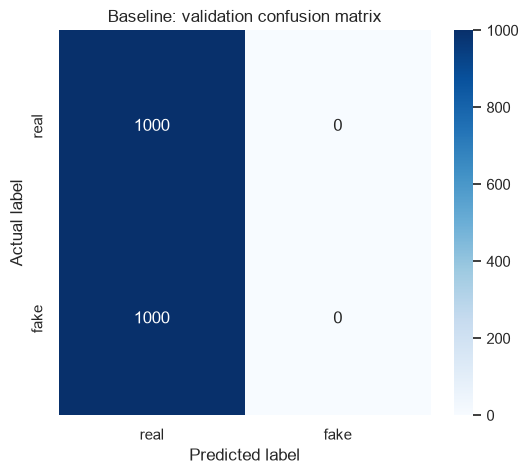

              precision    recall  f1-score   support

        real      0.500     1.000     0.667      1000
        fake      0.000     0.000     0.000      1000

    accuracy                          0.500      2000
   macro avg      0.250     0.500     0.333      2000
weighted avg      0.250     0.500     0.333      2000



In [36]:
def show_confusion(y_true, y_prob, title, file_name):
    # Heat map pattern from the Class 11 Sep notebook
    y_pred = (y_prob >= 0.5).astype(int)
    plt.figure(figsize=(6, 5))
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=class_order, yticklabels=class_order)
    plt.title(title)
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    save_fig(file_name)
    plt.show()
    print(classification_report(y_true, y_pred, target_names=class_order, digits=3, zero_division=0))

show_confusion(results["baseline"]["val_true"], results["baseline"]["val_prob"],
               "Baseline: validation confusion matrix", "13_baseline_confusion_matrix.png")

This code draws the confusion matrix as a heat map, following the pattern in the Class 11 Sep notebook, and prints the classification report. The rows are the actual classes and the columns are the predicted classes, so the diagonal holds the correct answers. The top right cell counts real faces wrongly called fake, and the bottom left cell counts fakes wrongly accepted as real, which is the error that matters most for this system. The classification report gives precision, recall and F1 for each class separately. The chart is saved as `figures/13_baseline_confusion_matrix.png`.

**What the output shows.** The confusion matrix confirms the problem: all 1,000 real faces are predicted real and all 1,000 fake faces are also predicted real, so the fake column is empty. The classification report gives real a recall of 1.000 and a precision of 0.500, and gives fake a precision, recall and F1 of 0.000. For the publisher this is the worst possible failure, because every fake face would be let through.

**Weaknesses of the baseline.** The baseline has four clear weaknesses. First, its training was unstable: the loss exploded from 0.69 to over 169 in training and 314 in validation, so the weights grew out of control instead of learning. Second, with no early stopping it kept the weights from its worst epoch (epoch 10) instead of its best (epoch 2). Third, it learned nothing useful, with a validation ROC AUC of 0.5025 and a final model that calls every face real, so it catches 0 of the 1,000 fake faces. Fourth, nothing in the model limits the dense layer that holds 97 percent of the parameters, and the heavy class augmentation (rotation of 0.2 and zoom of 0.3) may be hiding the fine details the task depends on. Section 5.5.1 later also shows that 14 of its 32 first layer filters had died. Each experiment below targets one of these weaknesses.

### 5.2 Retraining to Account for Weaknesses

Each experiment below changes one thing at a time, so that any change in the results can be traced back to that one change. Each one states which weakness it targets, what is changed and why, and ends with a comparison against the model before it. From Experiment 1 onwards early stopping is used with `monitor="val_loss"`, `patience=3` and `restore_best_weights=True`, with a limit of 15 epochs. Models are compared and chosen on validation F1 first and ROC AUC second; the test set is not used for any choice.

#### 5.2.1 Dropout and Early Stopping

**Weakness targeted.** The baseline kept the weights from its last and worst epoch although its validation loss was lowest at epoch 2, its loss exploded to over 300, and nothing limits how much its dense layer, which holds 3,211,392 of the 3,304,769 parameters, can rely on a few features.

**What is changed and why.** A `Dropout(0.5)` layer is added after `Flatten` and before the `Dense(128)` layer, and early stopping is switched on. Dropout switches off a random half of the flattened features at every training step, so the dense layer cannot lean on a few particular features and has to learn patterns that hold up more generally, which reduces overfitting (GeeksforGeeks, 2026d). It is placed there because the dense layer after `Flatten` holds most of the parameters of the model, so that is where memorising is most likely. Early stopping ends training once the validation loss stops improving and keeps the best epoch instead of the last one (GeeksforGeeks, 2026g).

In [37]:
exp1 = build_model(augmentation="class", dropout=0.5, name="exp1_dropout")
exp1_hist, exp1_record = train_model(exp1, epochs=15)
add_result("exp1_dropout", exp1, exp1_hist, exp1_record)

Epoch 1/15


313/313 - 15s - 46ms/step - accuracy: 0.5155 - loss: 0.6951 - val_accuracy: 0.5535 - val_loss: 0.7014


Epoch 2/15


313/313 - 13s - 41ms/step - accuracy: 0.5528 - loss: 0.6879 - val_accuracy: 0.5980 - val_loss: 0.6695


Epoch 3/15


313/313 - 13s - 42ms/step - accuracy: 0.5649 - loss: 0.6831 - val_accuracy: 0.5820 - val_loss: 0.6820


Epoch 4/15


313/313 - 13s - 41ms/step - accuracy: 0.5785 - loss: 0.6806 - val_accuracy: 0.5765 - val_loss: 0.7099


Epoch 5/15


313/313 - 13s - 40ms/step - accuracy: 0.5761 - loss: 0.6992 - val_accuracy: 0.5840 - val_loss: 0.6859


accuracy     0.5980
precision    0.5731
recall       0.7680
f1           0.6564
roc_auc      0.6377
log_loss     0.6695
Name: exp1_dropout, dtype: float64

This code builds the first experiment, which is the baseline with `Dropout(0.5)` added, trains it for up to 15 epochs with early stopping, and evaluates it on the validation set.

**What the output shows.** Experiment 1 trained for 5 epochs before early stopping ended it, and its best epoch was epoch 2, whose weights were restored. On the validation set it scored an accuracy of 0.5980, a precision of 0.5731, a recall of 0.7680, an F1 of 0.6564, a ROC AUC of 0.6377 and a log loss of 0.6695. Unlike the baseline, its loss never exploded and stayed between 0.67 and 0.71, and it now catches fakes, but its scores are still only modestly better than guessing.

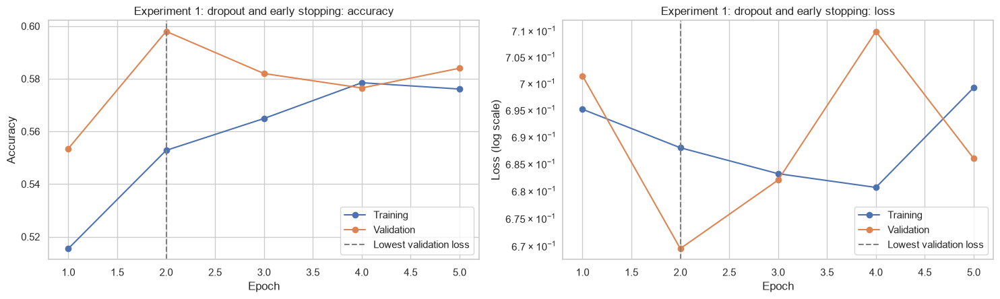

In [38]:
plot_history(exp1_hist, "Experiment 1: dropout and early stopping", "14_exp1_dropout_curves.png")

This code draws the training and validation curves for Experiment 1 with the same function as the baseline, so the two charts can be compared directly. The chart is saved as `figures/14_exp1_dropout_curves.png`.

**What the output shows.** The curves are much calmer than the baseline's. The loss stays close to 0.69 instead of exploding, and validation loss was lowest at epoch 2 (0.6695), after which it did not improve for three epochs, so training stopped at epoch 5. Training accuracy creeps up only slowly from 0.516 to 0.579, and validation accuracy stays between 0.554 and 0.598. Validation accuracy is above training accuracy for most of the run, because dropout and augmentation are only active during training and make the training images harder. The model is stable but is not learning much.

In [39]:
def compare_table(names):
    rows = []
    for n in names:
        r = results[n]
        rows.append({**r["record"], **{"val_" + k: v for k, v in r["val_scores"].items()}})
    return pd.DataFrame(rows).set_index("model").round(4)

def pick_best(names):
    # Highest validation F1 first; validation ROC AUC breaks ties
    return max(names, key=lambda n: (round(results[n]["val_scores"]["f1"], 3), results[n]["val_scores"]["roc_auc"]))

compare_table(["baseline", "exp1_dropout"])[["epochs_run", "best_epoch", "train_time_s", "overfit_gap",
                                              "val_accuracy", "val_precision", "val_recall", "val_f1", "val_roc_auc", "val_log_loss"]]

,epochs_run,best_epoch,train_time_s,overfit_gap,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,val_log_loss
model,,,,,,,,,,
baseline,10,2,125.0,0.0071,0.500,0.0000,0.000,0.0000,0.5025,7.9685
exp1_dropout,5,2,66.3,-0.0452,0.598,0.5731,0.768,0.6564,0.6377,0.6695


This code writes two helper functions that every later experiment uses. `compare_table` puts the training record and the validation scores of any set of models into one table, and `pick_best` chooses the best model of a group by validation F1, using validation ROC AUC to break ties when the F1 scores agree to three decimal places. The table then compares Experiment 1 with the baseline.

**What the output shows.** Compared with the baseline, Experiment 1 raised validation accuracy from 0.500 to 0.598, F1 from 0.000 to 0.656 and ROC AUC from 0.503 to 0.638, and cut the log loss from 7.97 to 0.67. It also took half the time (66.3 seconds against 125.0) because early stopping ended it after 5 epochs. Its overfitting gap is negative (minus 0.045), meaning training accuracy was lower than validation accuracy. So dropout and early stopping fixed the instability and the bad final weights, but the model is underfitting rather than overfitting, which points to the next weakness.

#### 5.2.2 Augmentation

**Weakness targeted.** Experiment 1 was stable but still learned very little. Its training accuracy never went above 0.579, its validation F1 was 0.656 and its ROC AUC 0.638, and its validation accuracy was higher than its training accuracy, which means the model was underfitting: the training images were harder for it than the validation images. The strongest remaining suspect is the class augmentation, which rotates and zooms every training image and, as the preview in 4.6 showed, blurs them and fills their corners with mirrored patterns.

**What is changed and why.** The augmentation is changed while everything else stays as in Experiment 1 (dropout and early stopping). Two new versions are trained: no augmentation at all, and a horizontal flip only. They are compared against the class augmentation already used in Experiment 1. The reasoning from 4.6 is that augmentation normally helps a CNN generalise (GeeksforGeeks, 2023), but rotation and zoom resample every pixel and fill the corners, which may blur the small textures that give a StyleGAN face away. A horizontal flip keeps every pixel exactly as it is, only mirrored, so it adds variety without blurring.

In [40]:
for kind in ["none", "flip"]:
    name = f"exp2_aug_{kind}"
    model = build_model(augmentation=kind, dropout=0.5, name=name)
    hist, record = train_model(model, epochs=15)
    add_result(name, model, hist, record)

Epoch 1/15


313/313 - 11s - 34ms/step - accuracy: 0.5059 - loss: 0.7035 - val_accuracy: 0.5150 - val_loss: 0.6927


Epoch 2/15


313/313 - 9s - 30ms/step - accuracy: 0.5238 - loss: 0.7264 - val_accuracy: 0.5355 - val_loss: 0.6857


Epoch 3/15


313/313 - 9s - 30ms/step - accuracy: 0.5244 - loss: 0.7221 - val_accuracy: 0.6040 - val_loss: 0.6785


... (28 outputs left out)

Epoch 3/15


313/313 - 10s - 33ms/step - accuracy: 0.5360 - loss: 5.5263 - val_accuracy: 0.5305 - val_loss: 4.4648


Epoch 4/15


313/313 - 10s - 33ms/step - accuracy: 0.5489 - loss: 6.9433 - val_accuracy: 0.4995 - val_loss: 16.5536


This code trains the two new augmentation settings in a loop, each with `Dropout(0.5)`, early stopping and a limit of 15 epochs, and evaluates both on the validation set.

**What the output shows.** The run with no augmentation learned steadily through all 15 epochs. Its validation accuracy climbed from 0.515 to 0.7775 at epoch 13, and its validation loss fell from 0.6927 to its lowest point of 0.4645 at epoch 14. Each epoch took about 10 seconds instead of about 13, since no augmentation has to be computed. The flip only run failed: its training loss was already 2.42 in the first epoch and grew to 6.94 by epoch 4, its validation loss was lowest at epoch 1 and then rose to 16.55, so early stopping ended it after 4 epochs.

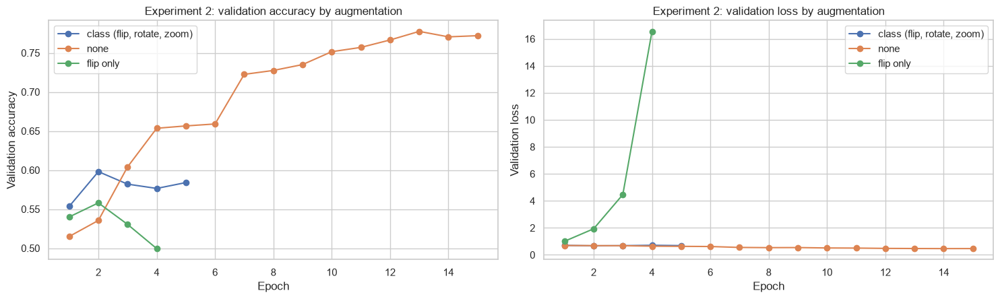

In [41]:
aug_runs = {"class (flip, rotate, zoom)": "exp1_dropout", "none": "exp2_aug_none", "flip only": "exp2_aug_flip"}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for label, name in aug_runs.items():
    hist = results[name]["history"]
    axes[0].plot(hist["epoch"], hist["val_accuracy"], marker="o", label=label)
    axes[1].plot(hist["epoch"], hist["val_loss"], marker="o", label=label)
for ax, metric in zip(axes, ["Validation accuracy", "Validation loss"]):
    ax.set_title(f"Experiment 2: {metric.lower()} by augmentation")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(metric)
    ax.legend()
plt.tight_layout()
save_fig("15_augmentation_comparison.png")
plt.show()

This code overlays the validation accuracy and validation loss of the three augmentation settings on the same axes, so it is easy to see which one learns fastest, which one reaches the best level and which one starts to overfit. The chart is saved as `figures/15_augmentation_comparison.png`.

**What the output shows.** The no augmentation line clearly separates from the other two. Its validation accuracy climbs steadily to above 0.77 and its validation loss falls smoothly, while the class augmentation line stays between 0.55 and 0.60 and the flip only line ends at about 0.50 with a validation loss that shoots upwards. No augmentation is the only setting that is still improving at the end.

In [42]:
best_aug_name = pick_best(list(aug_runs.values()))
best_aug = model_settings[best_aug_name]["augmentation"]
print("Best augmentation setting:", best_aug, f"({best_aug_name})")
compare_table(list(aug_runs.values()))[["epochs_run", "best_epoch", "train_time_s", "overfit_gap",
                                         "val_accuracy", "val_precision", "val_recall", "val_f1", "val_roc_auc", "val_log_loss"]]

Best augmentation setting: none (exp2_aug_none)


,epochs_run,best_epoch,train_time_s,overfit_gap,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,val_log_loss
model,,,,,,,,,,
exp1_dropout,5,2,66.3,-0.0452,0.5980,0.5731,0.768,0.6564,0.6377,0.6695
exp2_aug_none,15,14,142.5,0.0096,0.7705,0.7593,0.792,0.7753,0.8601,0.4645
exp2_aug_flip,4,1,42.2,-0.0351,0.5400,0.5433,0.502,0.5218,0.5657,1.0044


This code compares the three augmentation settings in one table and uses `pick_best` to choose the setting with the best validation F1 (with ROC AUC as the tie breaker). The chosen setting is carried into the next experiment.

**What the output shows.** No augmentation is chosen. It scores a validation accuracy of 0.7705, a precision of 0.7593, a recall of 0.792, an F1 of 0.7753, a ROC AUC of 0.8601 and a log loss of 0.4645, against an F1 of 0.6564 and a ROC AUC of 0.6377 for the class augmentation and an F1 of 0.5218 and a ROC AUC of 0.5657 for the flip only run. Its overfitting gap is only 0.010, so training without augmentation did not lead to overfitting on these 10,000 images. Removing rotation and zoom raised F1 by 0.119 and ROC AUC by 0.222, which supports the idea that these changes destroyed useful detail. The flip result should be read with care: since a flip does not blur the image, its failure is more likely to be the same unstable training seen in the baseline than a problem with flipping, and with one run per setting the two causes cannot be fully separated. This instability is what Experiment 3 targets.

#### 5.2.3 Learning Rate and Batch Size

**Weakness targeted.** Removing augmentation gave a big jump, but two problems remain. The model with no augmentation was still improving when it reached the 15 epoch limit (its best epoch was 14), so it learns slowly, and the flip only run blew up in its very first epoch with a training loss of 2.42, just like the baseline. A flip does not blur anything, so the more likely cause of both failures is the learning rate: the Adam default of 0.001 seems too large for a model whose dense layer has 3.2 million weights.

**What is changed and why.** This is a small seeded grid search in the style of Ice Task 3. It keeps the best settings so far (dropout and the best augmentation from Experiment 2) and tries two learning rates, 0.001 and 0.0001, with two batch sizes, 32 and 64, which gives four runs. The learning rate controls how big each weight update is: a large rate learns fast but can jump around and overshoot, while a small rate is steadier but slower. The batch size controls how many images are used for each update: larger batches give smoother updates and faster epochs but fewer updates per epoch. Each run is capped at 8 epochs, as in Ice Task 3, with the same early stopping, and the time of every run is recorded. The run with a learning rate of 0.001 and a batch size of 32 repeats the Experiment 2 settings under the same 8 epoch cap, so all four runs are compared on equal terms.

In [43]:
learning_rates = [0.001, 0.0001]
batch_sizes = [32, 64]
grid_epochs = 8
grid_names = []
for lr in learning_rates:
    for bs in batch_sizes:
        name = f"exp3_lr{lr}_bs{bs}"
        model = build_model(augmentation=best_aug, dropout=0.5, learning_rate=lr, name=name)
        hist, record = train_model(model, epochs=grid_epochs, batch_size=bs)
        add_result(name, model, hist, record)
        grid_names.append(name)

Epoch 1/8


313/313 - 11s - 34ms/step - accuracy: 0.5059 - loss: 0.7035 - val_accuracy: 0.5150 - val_loss: 0.6927


Epoch 2/8


313/313 - 9s - 30ms/step - accuracy: 0.5238 - loss: 0.7264 - val_accuracy: 0.5355 - val_loss: 0.6857


Epoch 3/8


313/313 - 10s - 30ms/step - accuracy: 0.5244 - loss: 0.7221 - val_accuracy: 0.6040 - val_loss: 0.6785


... (54 outputs left out)

Epoch 7/8


157/157 - 9s - 55ms/step - accuracy: 0.7909 - loss: 0.4509 - val_accuracy: 0.7920 - val_loss: 0.4590


Epoch 8/8


157/157 - 9s - 55ms/step - accuracy: 0.8059 - loss: 0.4278 - val_accuracy: 0.7795 - val_loss: 0.4659


This code sets the grid values and runs the grid search. For each of the two learning rates and each of the two batch sizes it builds a fresh model with the same seed, trains it for up to 8 epochs with early stopping and evaluates it on the validation set. Resetting the seed for every run, as in Ice Task 3, means the runs differ only in their learning rate and batch size.

**What the output shows.** All four runs used the full 8 epochs, which means none of them was stopped early. The run with a learning rate of 0.001 and a batch size of 32 produced exactly the same numbers in every epoch as the first 8 epochs of the no augmentation run in Experiment 2 (for example a validation accuracy of 0.7275 at epoch 8), which proves that resetting the seed makes the runs repeatable. The two runs with a learning rate of 0.0001 learned fastest from the start, reaching a validation accuracy of 0.6875 and 0.6485 after the first epoch, compared with 0.5150 for the 0.001 and batch 32 run. The batch size of 64 runs needed only 157 steps per epoch and took about 8.5 to 8.8 seconds per epoch instead of about 9.6 to 10.1.

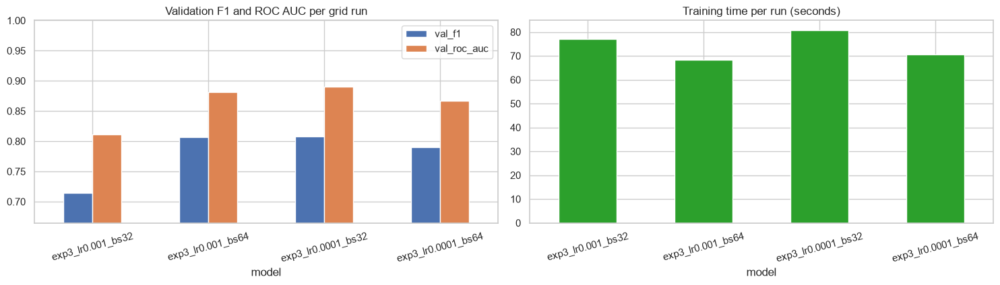

Best grid run: exp3_lr0.0001_bs32


,learning_rate,batch_size,epochs_run,best_epoch,train_time_s,time_per_epoch_s,overfit_gap,val_accuracy,val_f1,val_roc_auc,val_log_loss
model,,,,,,,,,,,
exp3_lr0.001_bs32,0.0010,32,8,8,77.0,9.6,-0.0155,0.7275,0.7148,0.8114,0.5348
exp3_lr0.001_bs64,0.0010,64,8,8,68.4,8.5,0.0289,0.7950,0.8071,0.8819,0.4440
exp3_lr0.0001_bs32,0.0001,32,8,8,80.8,10.1,0.0175,0.8135,0.8076,0.8898,0.4214
exp3_lr0.0001_bs64,0.0001,64,8,7,70.6,8.8,-0.0011,0.7920,0.7903,0.8668,0.4590


In [44]:
grid = compare_table(grid_names)
grid.insert(0, "learning_rate", [model_settings[n]["learning_rate"] for n in grid.index])
grid = grid[["learning_rate", "batch_size", "epochs_run", "best_epoch", "train_time_s", "time_per_epoch_s",
             "overfit_gap", "val_accuracy", "val_f1", "val_roc_auc", "val_log_loss"]]
grid.to_csv(out_dir / "grid_search_results.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
grid[["val_f1", "val_roc_auc"]].plot(kind="bar", ax=axes[0], rot=15)
axes[0].set_ylim(max(0.0, grid[["val_f1", "val_roc_auc"]].min().min() - 0.05), 1)
axes[0].set_title("Validation F1 and ROC AUC per grid run")
grid["train_time_s"].plot(kind="bar", ax=axes[1], rot=15, color="tab:green")
axes[1].set_title("Training time per run (seconds)")
plt.tight_layout()
save_fig("16_grid_search.png")
plt.show()

best_grid_name = pick_best(grid_names)
print("Best grid run:", best_grid_name)
grid

This code gathers the four grid runs into one table with their learning rate, batch size, epochs, best epoch, training time, time per epoch, overfitting gap and validation scores, and saves it as `outputs/grid_search_results.csv`. The chart shows validation F1 and ROC AUC for each run next to its training time, because a setting that is slightly better but much slower is not always worth it. `pick_best` then chooses the best run, and its learning rate and batch size are kept for Experiment 4. The chart is saved as `figures/16_grid_search.png`.

**What the output shows.** The best run uses a learning rate of 0.0001 and a batch size of 32. It reaches a validation accuracy of 0.8135, an F1 of 0.8076, a ROC AUC of 0.8898 and the lowest log loss of 0.4214, in 80.8 seconds. The run with a learning rate of 0.001 and a batch size of 64 comes very close on F1 (0.8071) but has a lower ROC AUC (0.8819) and a higher log loss (0.4440), and the original setting of 0.001 with batch 32 is clearly worst (F1 0.7148 and ROC AUC 0.8114). So both a smaller learning rate and a bigger batch help, and both make each update gentler. The batch 64 runs are about 11 to 13 percent faster, but the best run is only about 12 seconds slower than the fastest one, so its better scores are worth the time. The overfitting gaps are all small (0.029 at most). Every run's best epoch is 7 or 8, the last epochs allowed, so all four models were still improving when the cap stopped them, and more epochs would probably raise the scores further.

#### 5.2.4 Deeper Model

**Weakness targeted.** The best grid model reached a validation accuracy of 0.8135, but it still misses about one fake in five (validation recall 0.783). It also relies on a dense layer of 3.2 million parameters fed by a vector of 25,088 values, which gives it a lot of room to memorise. A deeper model could learn more abstract features while shrinking that vector.

**What is changed and why.** One more convolution block is added after the third one: `Conv2D(256)` with ReLU, then `BatchNormalization`, then `MaxPooling2D`. Everything else keeps the best settings so far. A fourth block lets the model combine the patterns found by the earlier layers into larger and more abstract features, and it also shrinks the feature maps before `Flatten`, so the dense layer receives a much shorter vector. Batch normalisation rescales the outputs of the new layer for each batch, which keeps training stable and can act as a mild regulariser (GeeksforGeeks, 2026c). The deeper model is only kept if it actually beats the best model so far on validation F1 and ROC AUC.

In [45]:
best_lr = model_settings[best_grid_name]["learning_rate"]
best_bs = results[best_grid_name]["record"]["batch_size"]
exp4 = build_model(augmentation=best_aug, dropout=0.5, extra_block=True, learning_rate=best_lr, name="exp4_deeper")
exp4_hist, exp4_record = train_model(exp4, epochs=15, batch_size=best_bs)
print(f"Settings: augmentation {best_aug}, learning rate {best_lr}, batch size {best_bs}")
add_result("exp4_deeper", exp4, exp4_hist, exp4_record)

Epoch 1/15


313/313 - 13s - 41ms/step - accuracy: 0.6422 - loss: 0.6363 - val_accuracy: 0.5160 - val_loss: 0.6694


Epoch 2/15


313/313 - 12s - 37ms/step - accuracy: 0.6992 - loss: 0.5862 - val_accuracy: 0.6300 - val_loss: 0.6135


Epoch 3/15


313/313 - 11s - 36ms/step - accuracy: 0.6948 - loss: 0.6540 - val_accuracy: 0.5740 - val_loss: 1.3918


... (2 outputs left out)

Epoch 5/15


313/313 - 11s - 36ms/step - accuracy: 0.6671 - loss: 0.8935 - val_accuracy: 0.6890 - val_loss: 0.7451


Settings: augmentation none, learning rate 0.0001, batch size 32


accuracy     0.6300
precision    0.8591
recall       0.3110
f1           0.4567
roc_auc      0.8109
log_loss     0.6135
Name: exp4_deeper, dtype: float64

This code builds the deeper model with the best augmentation, learning rate and batch size found so far, trains it for up to 15 epochs with early stopping and evaluates it on the validation set.

**What the output shows.** The deeper model has 1,569,345 parameters, less than half of the 3,304,769 in the other models, because the extra block shrinks the feature maps to 6 by 6 before `Flatten`. Its training was unstable: validation accuracy jumped from 0.516 to 0.630, fell to 0.574 and 0.543, then rose to 0.689, and validation loss spiked to about 1.4. Early stopping ended it after 5 epochs and restored epoch 2. On the validation set it scores an accuracy of 0.6300, a precision of 0.8591, a recall of only 0.3110, an F1 of 0.4567, a ROC AUC of 0.8109 and a log loss of 0.6135.

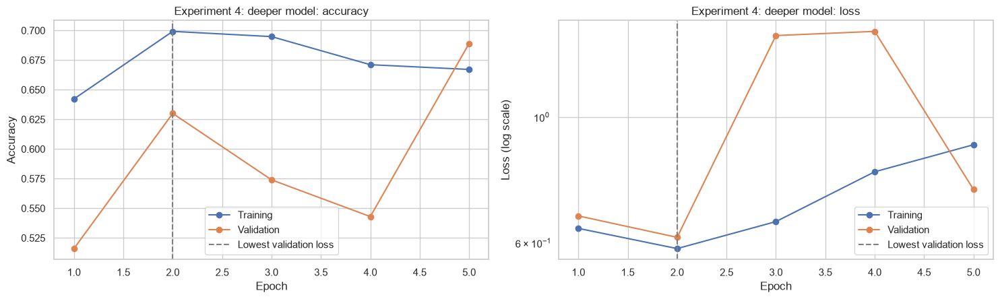

In [46]:
plot_history(exp4_hist, "Experiment 4: deeper model", "17_exp4_deeper_curves.png")

This code draws the training and validation curves of the deeper model with the same function as before. The chart is saved as `figures/17_exp4_deeper_curves.png`.

**What the output shows.** The training accuracy rises from 0.642 to 0.699 in the first two epochs and then slips back to 0.667, while the validation curves zigzag from epoch to epoch and the validation loss jumps from 0.61 at epoch 2 to about 1.4 at epochs 3 and 4. The model does not generalise its progress to new images in a stable way. A likely reason is the batch normalisation layer: early in training the statistics it learns from each batch still move a lot, so its behaviour on the validation set changes from epoch to epoch. Settling this would need more epochs or more tuning.

In [47]:
final_name = pick_best([best_grid_name, "exp4_deeper"])
print("Deeper model kept:", final_name == "exp4_deeper")
print("Chosen model     :", final_name)
compare_table([best_grid_name, "exp4_deeper"])[["parameters", "epochs_run", "best_epoch", "train_time_s", "overfit_gap",
                                                "val_accuracy", "val_precision", "val_recall", "val_f1", "val_roc_auc", "val_log_loss"]]

Deeper model kept: False
Chosen model     : exp3_lr0.0001_bs32


,parameters,epochs_run,best_epoch,train_time_s,overfit_gap,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,val_log_loss
model,,,,,,,,,,,
exp3_lr0.0001_bs32,3304769,8,8,80.8,0.0175,0.8135,0.8339,0.783,0.8076,0.8898,0.4214
exp4_deeper,1569345,5,2,57.9,0.0692,0.6300,0.8591,0.311,0.4567,0.8109,0.6135


This code compares the deeper model with the best model before it and keeps the deeper model only if `pick_best` prefers it on validation F1 and ROC AUC. The winner becomes the chosen model, `final_name`, which is the only model that will be tested on the test set besides the baseline.

**What the output shows.** The deeper model is not kept. Compared with the best grid model, its validation F1 falls from 0.8076 to 0.4567, its ROC AUC from 0.8898 to 0.8109 and its accuracy from 0.8135 to 0.6300, and its overfitting gap is larger (0.069 against 0.018). Its high precision (0.859) but very low recall (0.311) show that it only calls a face fake when it is very sure and lets most fakes through, which is the wrong trade for a security check. The chosen model is therefore `exp3_lr0.0001_bs32`: no augmentation, `Dropout(0.5)`, early stopping, a learning rate of 0.0001 and a batch size of 32.

### 5.3 Model Comparison

In [48]:
comparison = compare_table(list(results.keys()))
settings = pd.DataFrame(model_settings).T
comparison = settings.join(comparison, how="right")
comparison = comparison[["augmentation", "dropout", "extra_block", "learning_rate", "batch_size", "parameters",
                         "epochs_run", "best_epoch", "train_time_s", "overfit_gap", "val_accuracy",
                         "val_precision", "val_recall", "val_f1", "val_roc_auc", "val_log_loss"]]
comparison.to_csv(out_dir / "model_comparison.csv")
comparison

,augmentation,dropout,extra_block,learning_rate,batch_size,parameters,epochs_run,best_epoch,train_time_s,overfit_gap,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,val_log_loss
model,,,,,,,,,,,,,,,,
baseline,class,0.0,False,0.001,32,3304769,10,2,125.0,0.0071,0.5000,0.0000,0.000,0.0000,0.5025,7.9685
exp1_dropout,class,0.5,False,0.001,32,3304769,5,2,66.3,-0.0452,0.5980,0.5731,0.768,0.6564,0.6377,0.6695
exp2_aug_none,none,0.5,False,0.001,32,3304769,15,14,142.5,0.0096,0.7705,0.7593,0.792,0.7753,0.8601,0.4645
exp2_aug_flip,flip,0.5,False,0.001,32,3304769,4,1,42.2,-0.0351,0.5400,0.5433,0.502,0.5218,0.5657,1.0044
exp3_lr0.001_bs32,none,0.5,False,0.001,32,3304769,8,8,77.0,-0.0155,0.7275,0.7497,0.683,0.7148,0.8114,0.5348
exp3_lr0.001_bs64,none,0.5,False,0.001,64,3304769,8,8,68.4,0.0289,0.7950,0.7620,0.858,0.8071,0.8819,0.4440
exp3_lr0.0001_bs32,none,0.5,False,0.0001,32,3304769,8,8,80.8,0.0175,0.8135,0.8339,0.783,0.8076,0.8898,0.4214
exp3_lr0.0001_bs64,none,0.5,False,0.0001,64,3304769,8,7,70.6,-0.0011,0.7920,0.7967,0.784,0.7903,0.8668,0.4590
exp4_deeper,none,0.5,True,0.0001,32,1569345,5,2,57.9,0.0692,0.6300,0.8591,0.311,0.4567,0.8109,0.6135


This code builds one table of every model trained in this notebook, with its settings (augmentation, dropout, extra block, learning rate and batch size), its number of parameters, the epochs it ran, its best epoch, its training time, its overfitting gap and all six validation metrics. It is saved as `outputs/model_comparison.csv`, and it is the main table for the report.

**What the output shows.** Nine models were trained. The chosen model `exp3_lr0.0001_bs32` has the best validation accuracy (0.8135), F1 (0.8076) and ROC AUC (0.8898) and the lowest log loss (0.4214) of all of them. The table shows where the improvement came from. Dropout and early stopping took the baseline from an F1 of 0.000 to 0.656, removing augmentation took it to 0.775, and the lower learning rate took it to 0.808. The two runs whose loss blew up, the baseline and the flip only run, both combined augmentation with a learning rate of 0.001. The deeper model (F1 0.457) and the flip only run (F1 0.522) were steps backwards. Training times range from 42.2 seconds for the flip run, which stopped early, to 142.5 seconds for the 15 epoch run without augmentation.

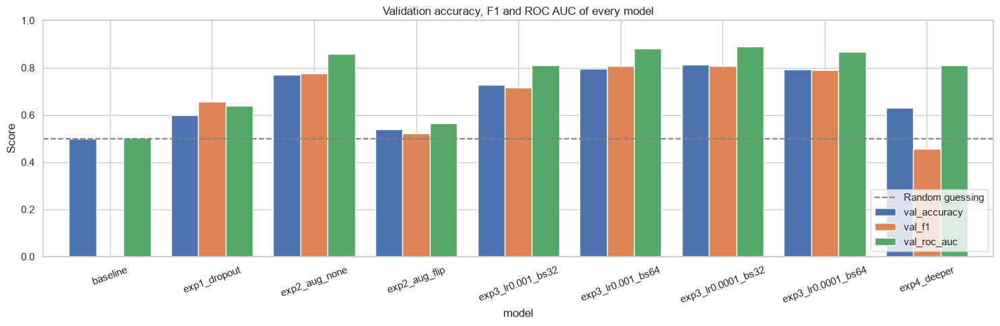

In [49]:
chart = comparison[["val_accuracy", "val_f1", "val_roc_auc"]]
ax = chart.plot(kind="bar", figsize=(15, 5), rot=20, width=0.8)
ax.set_ylim(max(0.0, chart.min().min() - 0.05), 1)
ax.set_title("Validation accuracy, F1 and ROC AUC of every model")
ax.set_ylabel("Score")
ax.axhline(0.5, color="grey", linestyle="--", label="Random guessing")
ax.legend(loc="lower right")
plt.tight_layout()
save_fig("18_model_comparison.png")
plt.show()

This code draws the validation accuracy, F1 and ROC AUC of every model as grouped bars, so the effect of each experiment can be seen in one picture. The vertical axis starts just below the lowest score so the differences between models are visible, and a dashed line marks random guessing where it fits on the axis. The chart is saved as `figures/18_model_comparison.png`.

**What the output shows.** The chart shows three groups. The baseline and the flip only run sit near the dashed line for random guessing, with F1 scores of 0.00 and 0.52. Experiment 1 and the deeper model are in the middle, the deeper model having a high ROC AUC but a low F1 because it misses most fakes. The no augmentation model and the grid models are clearly highest, with the chosen model the tallest group on all three measures.

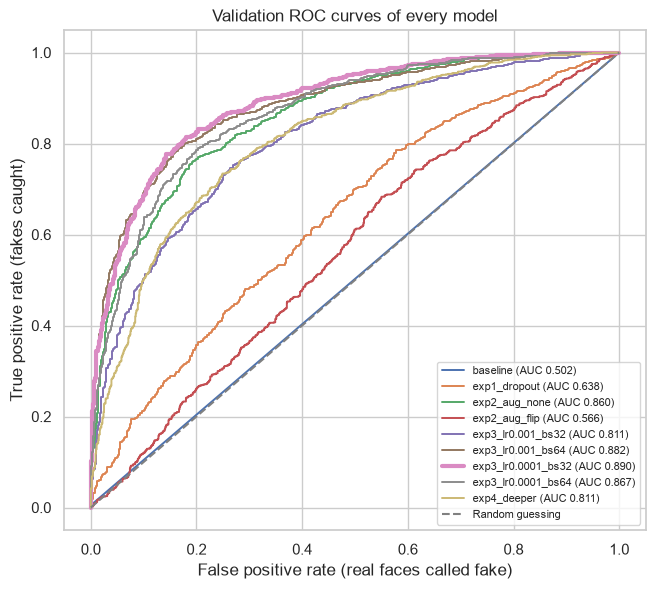

In [50]:
plt.figure(figsize=(7.5, 6.5))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(r["val_true"], r["val_prob"])
    width = 3 if name == final_name else 1.4
    plt.plot(fpr, tpr, linewidth=width, label=f"{name} (AUC {r['val_scores']['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guessing")
plt.xlabel("False positive rate (real faces called fake)")
plt.ylabel("True positive rate (fakes caught)")
plt.title("Validation ROC curves of every model")
plt.legend(fontsize=8, loc="lower right")
save_fig("19_roc_curves.png")
plt.show()

This code draws the ROC curve of every model on the validation set on one chart, with the chosen model drawn thicker. An ROC curve shows, for every possible cut off, the share of fakes caught against the share of real faces wrongly flagged (GeeksforGeeks, 2026b). A curve that bends towards the top left corner is better, and the diagonal is random guessing. The area under each curve is given in the legend. The chart is saved as `figures/19_roc_curves.png`.

**What the output shows.** The chosen model's curve (the thick line) bends furthest towards the top left corner, with an area of 0.890, followed closely by the 0.001 and batch 64 grid run (0.882). The baseline's curve lies on the diagonal (0.503), so it ranks faces no better than chance, and the flip only run (0.566) and Experiment 1 (0.638) sit only a little above it. The deeper model's curve (0.811) is reasonable, which confirms that its low F1 comes from where its cut off sits rather than from poor ranking.

### 5.4 Final Test Evaluation

The chosen model is now evaluated once on the 2,000 test images, which no model has seen and which played no part in any decision. The baseline is evaluated on the same test set so the improvement can be measured, and both are compared with random guessing.

In [51]:
test_scores = {}
for name in ["baseline", final_name]:
    scores, y_true, y_prob = evaluate_model(results[name]["model"], test_ds)
    test_scores[name] = scores
    results[name]["test_true"], results[name]["test_prob"] = y_true, y_prob

# Expected scores of a coin toss on balanced classes (a constant 0.5 gives the log loss)
test_scores["random guessing"] = {"accuracy": 0.5, "precision": 0.5, "recall": 0.5, "f1": 0.5,
                                  "roc_auc": 0.5, "log_loss": np.log(2)}
test_table = pd.DataFrame(test_scores).T.round(4)
test_table.to_csv(out_dir / "test_results.csv")
test_table

,accuracy,precision,recall,f1,roc_auc,log_loss
baseline,0.500,0.0000,0.000,0.000,0.5020,7.9701
exp3_lr0.0001_bs32,0.809,0.8359,0.769,0.801,0.8898,0.4222
random guessing,0.500,0.5000,0.500,0.500,0.5000,0.6931


This code evaluates the baseline and the chosen model on the test set with the same evaluation function as before, and stores their test predictions for the interpretation section. It adds a row for random guessing: on two balanced classes a coin toss is expected to score 0.5 on accuracy, precision, recall, F1 and ROC AUC, and always answering 0.5 gives a log loss of about 0.693. The table is saved as `outputs/test_results.csv`.

**What the output shows.** On the 2,000 unseen test images the chosen model scores an accuracy of 0.809, a precision of 0.8359, a recall of 0.769, an F1 of 0.801, a ROC AUC of 0.8898 and a log loss of 0.4222. These are very close to its validation scores (0.8135 accuracy and 0.8898 ROC AUC), which shows that choosing the model on the validation set did not make it look better than it really is. The baseline scores 0.500 accuracy, 0.000 F1, a ROC AUC of 0.5020 and a log loss of 7.9701 on the same test set, the same as on validation. The chosen model is 30.9 percentage points more accurate than both the baseline and random guessing, and its log loss of 0.42 is well below the 0.693 of always answering 0.5.

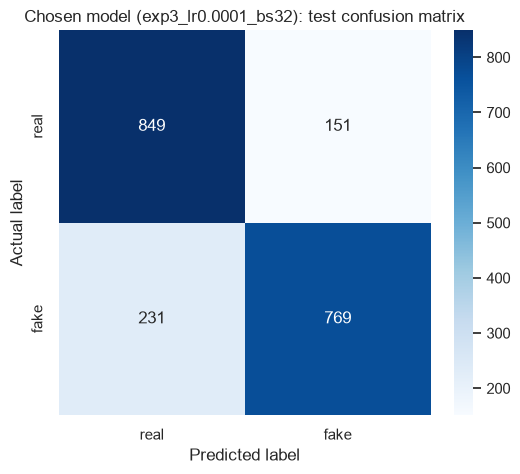

              precision    recall  f1-score   support

        real      0.786     0.849     0.816      1000
        fake      0.836     0.769     0.801      1000

    accuracy                          0.809      2000
   macro avg      0.811     0.809     0.809      2000
weighted avg      0.811     0.809     0.809      2000



In [52]:
show_confusion(results[final_name]["test_true"], results[final_name]["test_prob"],
               f"Chosen model ({final_name}): test confusion matrix", "20_final_test_confusion_matrix.png")

This code draws the test confusion matrix of the chosen model and prints its classification report, with the same layout as for the baseline in 5.1. The chart is saved as `figures/20_final_test_confusion_matrix.png`.

**What the output shows.** Of the 1,000 real test faces, 849 are correctly accepted and 151 are wrongly flagged as fake. Of the 1,000 fake faces, 769 are caught and 231 are wrongly accepted as real. The classification report gives the real class a precision of 0.786 and a recall of 0.849, and the fake class a precision of 0.836 and a recall of 0.769. So the model is better at recognising real faces than at catching fakes. For the publisher the main remaining weakness is that 23.1 percent of fakes still get through. Lowering the probability cut off below 0.5 would catch more fakes at the cost of flagging more real people.

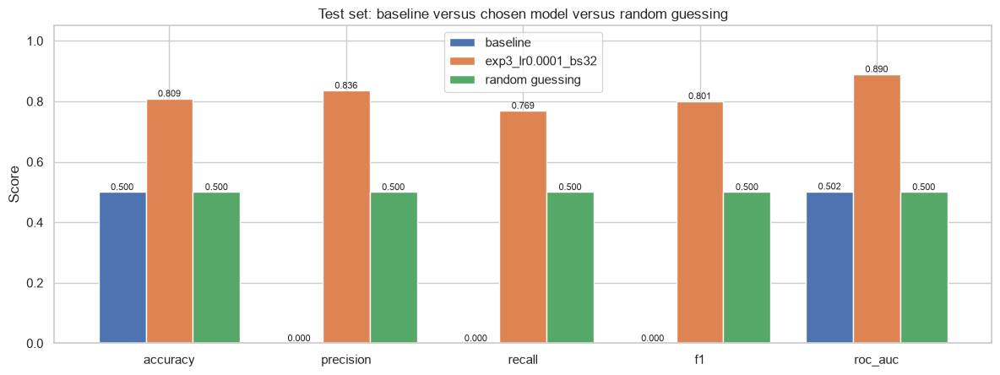

In [53]:
ax = test_table[["accuracy", "precision", "recall", "f1", "roc_auc"]].T.plot(kind="bar", figsize=(12, 4.6), rot=0, width=0.8)
ax.set_ylim(0, 1.05)
ax.set_title("Test set: baseline versus chosen model versus random guessing")
ax.set_ylabel("Score")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8)
plt.tight_layout()
save_fig("21_test_comparison.png")
plt.show()

This code draws the test scores of the baseline, the chosen model and random guessing as grouped bars with the value written on each bar, so the size of the improvement is easy to see. The chart is saved as `figures/21_test_comparison.png`.

**What the output shows.** The bars make the gap obvious. The chosen model scores between 0.769 and 0.890 on every measure, while random guessing is 0.500 on all of them and the baseline is 0.500 on accuracy and ROC AUC and 0.000 on precision, recall and F1. Recall, at 0.769, is the chosen model's lowest bar, which matches the 231 missed fakes in the confusion matrix.

### 5.5 Interpretation

#### 5.5.1 What the CNN Looks At

As planned in 4.6, this section shows the feature maps of the first convolution layer for one real and one fake test face. A feature map is the output of one filter: bright areas are where that filter found its pattern. The maps come from the chosen model rather than the baseline, because the baseline's training blew up in 5.1 and left most of its first layer filters switched off, so its maps would show very little. The next cell measures this so the choice is backed by numbers.

In [54]:
def load_for_model(path):
    # Same steps as image_dataset_from_directory: decode, resize to 128 by 128 (bilinear) and add the batch dimension
    image = tf.io.decode_image(tf.io.read_file(str(path)), channels=3, expand_animations=False)
    return tf.expand_dims(tf.image.resize(image, (img_size, img_size)), axis=0)

def first_layer_maps(model, batch):
    # A small model that shares the trained layers but stops after the first convolution layer
    first_conv = [layer for layer in model.layers if isinstance(layer, layers.Conv2D)][0]
    return tf.keras.Model(inputs=model.inputs, outputs=first_conv.output).predict(batch, verbose=0)[0]

final_model = results[final_name]["model"]
picks = [subset_df[(subset_df["subset_split"] == "test") & (subset_df["label"] == l)].iloc[0] for l in classes]
batches = [load_for_model(row["subset_path"]) for row in picks]
for name, model in [("baseline", baseline), (final_name, final_model)]:
    maps = [first_layer_maps(model, b) for b in batches]
    dead = int(np.all([m.max(axis=(0, 1)) == 0 for m in maps], axis=0).sum())
    print(f"{name:<20} filters that output nothing for both faces: {dead} of {maps[0].shape[-1]}")
final_maps = [first_layer_maps(final_model, b) for b in batches]

baseline             filters that output nothing for both faces: 14 of 32


exp3_lr0.0001_bs32   filters that output nothing for both faces: 0 of 32


This code writes a small `load_for_model` function that prepares a single image in exactly the same way as `image_dataset_from_directory` did during training: it decodes the JPEG, resizes it to 128 by 128 with bilinear resizing and adds the batch dimension. Matching the training steps matters, because a different resizing method would give the model slightly different pixels from what it learned on. A second function, `first_layer_maps`, builds a small model that shares a trained model's layers but stops after the first convolution layer, and returns its 32 feature maps for one image. The code passes one real and one fake test face through both the baseline and the chosen model and counts the filters that output nothing at all for both faces. A filter like that is called a dead ReLU filter: its weights have been pushed so far that ReLU turns every value into zero, so it no longer contributes anything.

**What the output shows.** In the baseline, 14 of the 32 first layer filters output nothing at all for either face, so almost half of its first layer is dead. This is a lasting side effect of the exploding loss in 5.1, and it explains why its feature maps would show little. The chosen model has 0 dead filters, so every filter is still doing work. The two `WARNING:tensorflow` lines about retracing are harmless messages that appear because a new small model is built for each face. They are not errors and they do not change any result.

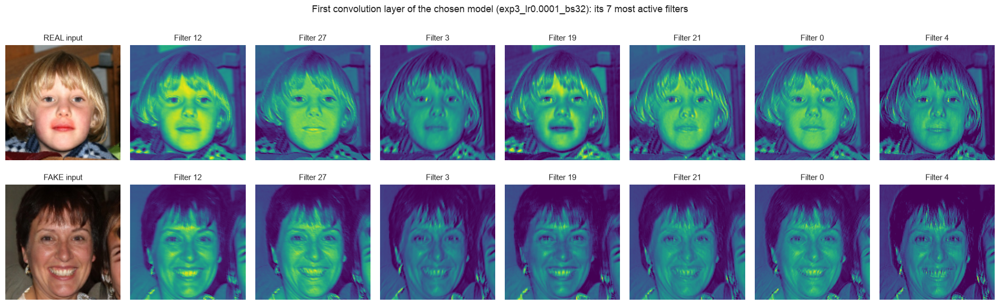

In [55]:
# Show the seven most active filters of the chosen model for the same two faces
activity = final_maps[0].mean(axis=(0, 1)) + final_maps[1].mean(axis=(0, 1))
top_filters = np.argsort(-activity)[:7]

fig, axes = plt.subplots(2, 8, figsize=(19, 6.2))
for r, (row, batch, maps) in enumerate(zip(picks, batches, final_maps)):
    axes[r, 0].imshow(batch[0].numpy().astype("uint8"))
    axes[r, 0].set_title(f"{row['label'].upper()} input", fontsize=11)
    for c, f in enumerate(top_filters, start=1):
        axes[r, c].imshow(maps[:, :, f], cmap="viridis")
        axes[r, c].set_title(f"Filter {f}", fontsize=11)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle(f"First convolution layer of the chosen model ({final_name}): its 7 most active filters", fontsize=13)
plt.tight_layout()
save_fig("22_feature_maps.png")
plt.show()

This code picks the seven filters of the chosen model that respond most strongly, on average, to the two faces, and shows the input next to their feature maps. The same seven filters are shown for the real and the fake face, so the two rows can be compared directly. The chart is saved as `figures/22_feature_maps.png`.

**What the output shows.** The seven most active filters are numbers 12, 27, 3, 19, 21, 0 and 4. All of them respond to edges and textures: the outline of the face, the strands of the hair and fringe, the eyes, the lips and teeth, and the patterned clothing. Some filters (such as 12 and 19) light up the smooth skin brightly, while others (such as 3, 0 and 4) light up mainly fine edges like hair strands, eyelids and teeth. On the fake face the strongest responses are around the hair and the teeth of the smile, which are the same regions that the average face difference map in 4.4.6 highlighted. This shows that even the first layer focuses on the fine local details where generated faces tend to differ, rather than on the background.

#### 5.5.2 Confidence and Mistakes

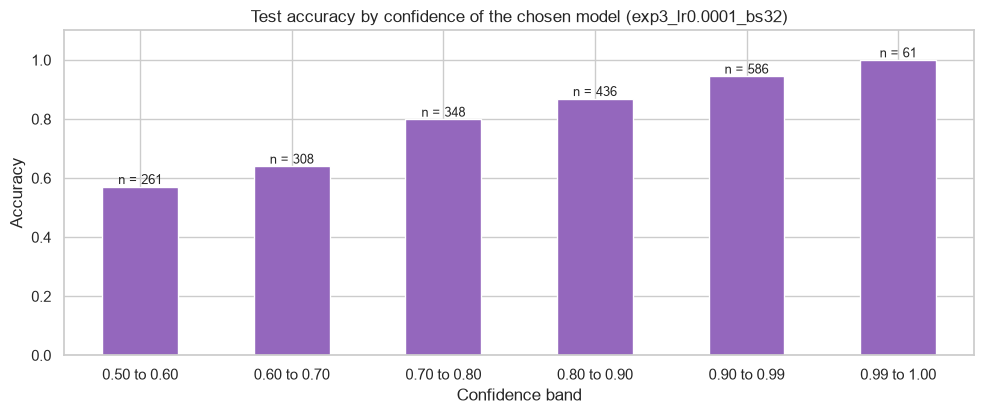

,images,accuracy
band,,
0.50 to 0.60,261,0.571
0.60 to 0.70,308,0.640
0.70 to 0.80,348,0.799
0.80 to 0.90,436,0.869
0.90 to 0.99,586,0.945
0.99 to 1.00,61,1.000


In [56]:
conf_df = pd.DataFrame({"path": test_raw.file_paths, "actual": results[final_name]["test_true"],
                        "prob_fake": results[final_name]["test_prob"]})
conf_df["predicted"] = (conf_df["prob_fake"] >= 0.5).astype(int)
conf_df["confidence"] = np.where(conf_df["predicted"] == 1, conf_df["prob_fake"], 1 - conf_df["prob_fake"])
conf_df["correct"] = conf_df["predicted"] == conf_df["actual"]
conf_df["band"] = pd.cut(conf_df["confidence"], bins=[0.5, 0.6, 0.7, 0.8, 0.9, 0.99, 1.0], include_lowest=True,
                         labels=["0.50 to 0.60", "0.60 to 0.70", "0.70 to 0.80", "0.80 to 0.90", "0.90 to 0.99", "0.99 to 1.00"])

bands = conf_df.groupby("band", observed=False).agg(images=("correct", "size"), accuracy=("correct", "mean")).round(3)
bands.to_csv(out_dir / "confidence_bands.csv")
ax = bands["accuracy"].plot(kind="bar", figsize=(10, 4.3), rot=0, color="tab:purple")
for patch, n in zip(ax.patches, bands["images"]):
    ax.annotate(f"n = {n}", (patch.get_x() + patch.get_width() / 2, patch.get_height()), ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, 1.1)
ax.set_title(f"Test accuracy by confidence of the chosen model ({final_name})")
ax.set_xlabel("Confidence band")
ax.set_ylabel("Accuracy")
plt.tight_layout()
save_fig("23_confidence_bands.png")
plt.show()
bands

This code measures how far the chosen model's confidence can be trusted. For every test image it takes the probability of fake, turns it into a prediction and a confidence (the probability of whichever class was predicted, so always between 0.5 and 1), and groups the images into confidence bands. For each band it reports how many images fall in it and how accurate the model was on them. A trustworthy model should be most accurate when it is most confident, which also suggests how the publisher could use it: faces the model is unsure about could be sent to a person to check. The chart is saved as `figures/23_confidence_bands.png` and the table as `outputs/confidence_bands.csv`.

**What the output shows.** Accuracy rises steadily with confidence, so the model's confidence can be trusted. When the model is between 0.50 and 0.60 sure (261 images), it is right only 57.1 percent of the time, which is little better than guessing. Accuracy rises to 64.0 percent between 0.60 and 0.70 (308 images), 79.9 percent between 0.70 and 0.80 (348 images) and 86.9 percent between 0.80 and 0.90 (436 images). Above 0.90 confidence (647 images) it is right about 95 percent of the time, and all 61 images above 0.99 are correct. This suggests a practical way to use the model: accept its answer automatically when it is very confident, and send the roughly 28 percent of faces with a confidence below 0.70 to a person to check.

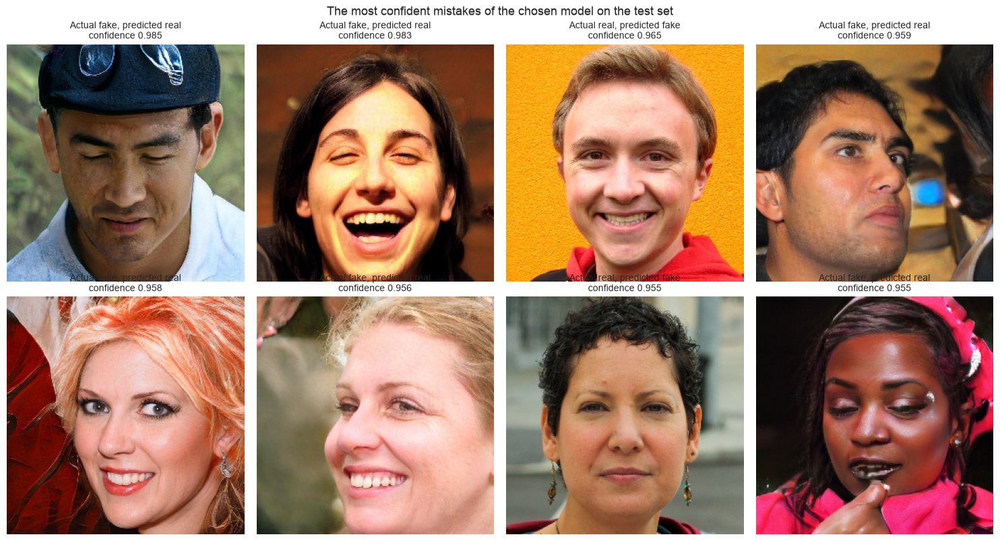

Mistakes in total: 382 of 2000
actual
fake    6
real    2
Name: count, dtype: int64


In [57]:
mistakes = conf_df[~conf_df["correct"]].nlargest(8, "confidence")
fig, axes = plt.subplots(2, 4, figsize=(15, 8.2))
for ax in axes.ravel():
    ax.axis("off")
for ax, (_, row) in zip(axes.ravel(), mistakes.iterrows()):
    ax.imshow(Image.open(row["path"]))
    ax.set_title(f"Actual {class_order[row['actual']]}, predicted {class_order[row['predicted']]}\n"
                 f"confidence {row['confidence']:.3f}", fontsize=10)
plt.suptitle("The most confident mistakes of the chosen model on the test set", fontsize=13)
plt.tight_layout()
save_fig("24_confident_mistakes.png")
plt.show()
print("Mistakes in total:", int((~conf_df["correct"]).sum()), "of", len(conf_df))
print(mistakes.assign(actual=mistakes["actual"].map(dict(enumerate(class_order))))["actual"].value_counts())

This code finds the eight test images that the chosen model got wrong with the highest confidence and shows them with their actual class, the predicted class and the confidence. Error analysis like this, as in my Part 1, shows what kind of images still fool the model, which is more useful than a single score when deciding how to improve it. The code also prints the total number of mistakes and how many of the confident mistakes were real faces and how many were fakes. The chart is saved as `figures/24_confident_mistakes.png`.

**What the output shows.** The chosen model made 382 mistakes on the 2,000 test images (19.1 percent). Its eight most confident mistakes, with confidences from 0.955 to 0.985, are six fakes accepted as real and two real faces flagged as fake, the same pattern as the confusion matrix. Some of the fakes it accepted have visible generator errors that a person might notice, such as the strange shiny shapes on the cap in the first image and the strange white smudges on the lips and scarf in the last one, but these errors are small at 128 by 128 and the model misses them. The two real faces it flagged look smooth, evenly lit and posed against plain backgrounds, which is exactly the clean look of many generated faces. Note that the second row's titles slightly overlap the first row's images; the labels can still be read.

#### 5.5.3 Using the Model

In [58]:
def predict_image(path, model=final_model):
    # Returns ("real" or "fake", probability of that answer) for one image file
    prob_fake = float(model.predict(load_for_model(path), verbose=0)[0, 0])
    return ("fake", prob_fake) if prob_fake >= 0.5 else ("real", 1 - prob_fake)

demo = pd.concat([subset_df[(subset_df["subset_split"] == "test") & (subset_df["label"] == l)].sample(3, random_state=seed)
                  for l in classes])
rows = []
for _, row in demo.iterrows():
    answer, probability = predict_image(row["subset_path"])
    rows.append({"file": Path(row["subset_path"]).name, "actual": row["label"],
                 "prediction": answer, "probability": round(probability, 4)})
pd.DataFrame(rows)

,file,actual,prediction,probability
0,real_36271.jpg,real,real,0.7318
1,real_19417.jpg,real,real,0.9193
2,real_41519.jpg,real,real,0.7265
3,fake_IL3PGDMOUE.jpg,fake,real,0.5113
4,fake_9T4XSZTLUN.jpg,fake,fake,0.6636
5,fake_L5GIGGZJA6.jpg,fake,fake,0.6852


This code ends with a `predict_image` function that the publisher's system could call for any face image. It uses the chosen model, `final_model`, set in 5.5.1, and prepares the image with the same `load_for_model` steps used in training, asks the chosen model for the probability that the face is fake, and returns the answer "real" or "fake" together with the probability of that answer. The code demonstrates it on three real and three fake test faces chosen at random with the seed and shows the file name, the actual class, the prediction and the probability for each.

**What the output shows.** The function answered correctly for five of the six faces. The three real faces were called real with probabilities of 0.7318, 0.9193 and 0.7265. Two fakes were caught with probabilities of 0.6636 and 0.6852, and one fake (`fake_IL3PGDMOUE.jpg`) was called real with a probability of only 0.5113, which is barely more than a coin toss. Under the confidence based use suggested in 5.5.2, this face would have been sent to a person to check instead of being trusted.

### Summary of Key Numbers

In [59]:
def line(label, value):
    print(f"{label:<44} {value}")

print("DATA")
line("Full dataset images", f"{len(full_df):,} ({(full_df['label'] == 'real').sum():,} real, {(full_df['label'] == 'fake').sum():,} fake)")
line("Working subset images", f"{len(subset_df):,} (train {recount_df.loc['train', 'total']:,}, val {recount_df.loc['val', 'total']:,}, test {recount_df.loc['test', 'total']:,})")
line("Corrupt / nearly blank / duplicate files", f"{n_corrupt} / {n_blank} / {n_dups}")
line("Files shared between subset splits", sum(len(hashes[a] & hashes[b]) for a, b in [("train", "val"), ("train", "test"), ("val", "test")]))
line("Best single property rule (validation acc.)", f"{rules.loc[rules['Validation accuracy'].idxmax(), 'Measure']}: {rules['Validation accuracy'].max():.3f}")
print("\nMODELS")
for name in ["baseline", final_name]:
    s, r = model_settings[name], results[name]["record"]
    line(f"{name} settings", f"aug {s['augmentation']}, dropout {s['dropout']}, extra block {s['extra_block']}, lr {s['learning_rate']}, batch {r['batch_size']}")
    line(f"{name} parameters / epochs / time", f"{r['parameters']:,} / {r['epochs_run']} (best {r['best_epoch']}) / {r['train_time_s']} s")
    v, t = results[name]["val_scores"], test_scores[name]
    line(f"{name} validation acc / F1 / AUC", f"{v['accuracy']:.4f} / {v['f1']:.4f} / {v['roc_auc']:.4f}")
    line(f"{name} test acc / prec / rec / F1 / AUC", f"{t['accuracy']:.4f} / {t['precision']:.4f} / {t['recall']:.4f} / {t['f1']:.4f} / {t['roc_auc']:.4f}")
line("Total training time, all models", f"{sum(r['record']['train_time_s'] for r in results.values()) / 60:.1f} minutes")

DATA
Full dataset images                          140,000 (70,000 real, 70,000 fake)
Working subset images                        14,000 (train 10,000, val 2,000, test 2,000)
Corrupt / nearly blank / duplicate files     0 / 0 / 0
Files shared between subset splits           0
Best single property rule (validation acc.)  File size (KB): 0.540

MODELS
baseline settings                            aug class, dropout 0.0, extra block False, lr 0.001, batch 32
baseline parameters / epochs / time          3,304,769 / 10 (best 2) / 125.0 s
baseline validation acc / F1 / AUC           0.5000 / 0.0000 / 0.5025
baseline test acc / prec / rec / F1 / AUC    0.5000 / 0.0000 / 0.0000 / 0.0000 / 0.5020
exp3_lr0.0001_bs32 settings                  aug none, dropout 0.5, extra block False, lr 0.0001, batch 32
exp3_lr0.0001_bs32 parameters / epochs / time 3,304,769 / 8 (best 8) / 80.8 s
exp3_lr0.0001_bs32 validation acc / F1 / AUC 0.8135 / 0.8076 / 0.8898
exp3_lr0.0001_bs32 test acc / prec / rec / F1 / A

This code prints one clean summary of the numbers the report needs: the size of the full dataset and the working subset, the data quality findings, the result of the shortcut check, the settings, size and training time of the baseline and the chosen model, their validation and test scores, and the total training time of all the models together.

**What the output shows.** The summary brings the key numbers together. The full dataset has 140,000 images (70,000 real and 70,000 fake), and the working subset has 14,000 (10,000 for training, 2,000 for validation and 2,000 for testing). There are 0 corrupt, 0 nearly blank and 0 duplicate files, and 0 files are shared between the subset splits. The best single property rule, based on file size, reaches only 0.540 on validation. The baseline used the class augmentation, no dropout, a learning rate of 0.001 and a batch size of 32, had 3,304,769 parameters and trained for 10 epochs in 125.0 seconds. It scored 0.500 accuracy, 0.000 F1 and 0.5025 ROC AUC on validation, and 0.500 accuracy, 0.000 F1 and 0.5020 ROC AUC on test. The chosen model `exp3_lr0.0001_bs32` used no augmentation, `Dropout(0.5)`, a learning rate of 0.0001 and a batch size of 32, had the same 3,304,769 parameters and trained for 8 epochs in 80.8 seconds. It scored 0.8135 accuracy, 0.8076 F1 and 0.8898 ROC AUC on validation, and 0.8090 accuracy, 0.8359 precision, 0.7690 recall, 0.8010 F1 and 0.8898 ROC AUC on test. All nine models together trained in 12.2 minutes, and the whole notebook ran in under 14 minutes on the M4.

## References

Anthropic (2026) *Claude Opus 5.5* [Large language model]. Available at: https://claude.ai (Accessed: 19 November 2026).

GeeksforGeeks (2023) *Python | Data Augmentation*. Available at: https://www.geeksforgeeks.org/machine-learning/python-data-augmentation/ (Accessed: 19 November 2026).

GeeksforGeeks (2026a) *Activation Functions in Neural Networks*. Available at: https://www.geeksforgeeks.org/machine-learning/activation-functions-neural-networks/ (Accessed: 19 November 2026).

GeeksforGeeks (2026b) *AUC-ROC Curve in Machine Learning*. Available at: https://www.geeksforgeeks.org/machine-learning/auc-roc-curve/ (Accessed: 19 November 2026).

GeeksforGeeks (2026c) *Batch Normalization In Deep Learning*. Available at: https://www.geeksforgeeks.org/deep-learning/batch-normalization-in-deep-learning-2/ (Accessed: 19 November 2026).

GeeksforGeeks (2026d) *Dropout in Neural Networks*. Available at: https://www.geeksforgeeks.org/machine-learning/dropout-in-neural-networks/ (Accessed: 19 November 2026).

GeeksforGeeks (2026e) *Introduction to Convolution Neural Network*. Available at: https://www.geeksforgeeks.org/machine-learning/introduction-convolution-neural-network/ (Accessed: 19 November 2026).

GeeksforGeeks (2026f) *Introduction to Pooling Layer in CNN*. Available at: https://www.geeksforgeeks.org/deep-learning/introduction-to-pooling-layer-cnn/ (Accessed: 19 November 2026).

GeeksforGeeks (2026g) *Regularization by Early Stopping*. Available at: https://www.geeksforgeeks.org/machine-learning/regularization-by-early-stopping/ (Accessed: 19 November 2026).

Karras, T., Laine, S. and Aila, T. (2019) 'A Style-Based Generator Architecture for Generative Adversarial Networks', *arXiv preprint*, arXiv:1812.04948. Available at: https://arxiv.org/abs/1812.04948 (Accessed: 19 November 2026).

TensorFlow (2026) *Image classification*. Available at: https://www.tensorflow.org/tutorials/images/classification (Accessed: 19 November 2026).

xhlulu (2020) *140k Real and Fake Faces*. Kaggle. Available at: https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces (Accessed: 19 November 2026).